# Fatigue factor analysis by sleep-duration group(睡眠時間グループ別の疲労要因分析)

RQ:Does the effect of each behavioural factor (e.g., bedtime phone use, caffeine) on next-day fatigue differ across sleep-duration groups?

RQ(日本語):寝る前のスマホ利用やカフェインなどの各要素が翌日の疲労に与える影響は、睡眠時間のグループによって異なるか？

## Step 1:Data collection(データ収集)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 日本語を表示するためのフォント（macOS）
plt.rcParams["font.family"] = "Hiragino Sans"

# データの読み込み
DATA_PATH = "bedtime_screentime_sleep_debt.csv"
df = pd.read_csv(DATA_PATH)

print(f"Rows(行数):{df.shape[0]}")
print(f"Columns(列数):{df.shape[1]}")
print("Column names(列名):")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}.{col}")

Rows(行数):8500
Columns(列数):18
Column names(列名):
1.user_id
2.age
3.gender
4.occupation_type
5.chronotype
6.bedtime_phone_minutes
7.primary_bedtime_app
8.screen_brightness_pct
9.blue_light_filter_active
10.caffeine_post_5pm_mg
11.physical_activity_min
12.sleep_latency_min
13.total_sleep_hours
14.deep_sleep_pct
15.rem_sleep_pct
16.morning_alarm_snoozes
17.next_day_fatigue_score
18.sleep_debt_category


In [2]:
# 先頭5行の確認
df.head()

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


## Step 2:Data understanding(データの理解)

In [3]:
# 型、欠損値、重複
info = pd.DataFrame({
    "Data type(型)": df.dtypes.astype(str),
    "Missing(欠損数)": df.isna().sum(),
})
print("Data types and missing values(型と欠損値):")
print(info.to_string())
print(f"Total missing(欠損数の合計):{df.isna().sum().sum()}")

# 重複の確認
print(f"Duplicated user_id(user_idの重複数):{df['user_id'].duplicated().sum()}")
print(f"Duplicated rows(完全に同じ行の数):{df.duplicated().sum()}")
print(f"Duplicated rows without user_id(user_id以外が同じ行の数):{df.drop(columns='user_id').duplicated().sum()}")

Data types and missing values(型と欠損値):
                         Data type(型)  Missing(欠損数)
user_id                           str             0
age                             int64             0
gender                            str             0
occupation_type                   str             0
chronotype                        str             0
bedtime_phone_minutes           int64             0
primary_bedtime_app               str             0
screen_brightness_pct           int64             0
blue_light_filter_active        int64             0
caffeine_post_5pm_mg            int64             0
physical_activity_min           int64             0
sleep_latency_min             float64             0
total_sleep_hours             float64             0
deep_sleep_pct                float64             0
rem_sleep_pct                 float64             0
morning_alarm_snoozes           int64             0
next_day_fatigue_score        float64             0
sleep_debt_category       

Descriptive statistics(記述統計):
                           count       mean        std   min    25%    50%    75%    max
age                       8500.0  34.355647  11.584259  18.0  25.00  32.00  42.00   65.0
bedtime_phone_minutes     8500.0  59.250000  36.931991   1.0  31.00  51.00  79.00  180.0
screen_brightness_pct     8500.0  55.153882  19.850550  10.0  42.00  55.00  69.00  100.0
blue_light_filter_active  8500.0   0.467765   0.498989   0.0   0.00   0.00   1.00    1.0
caffeine_post_5pm_mg      8500.0  33.222471  51.935645   0.0   0.00   0.00  55.00  250.0
physical_activity_min     8500.0  35.701412  20.819390   0.0  21.00  35.00  50.00  112.0
sleep_latency_min         8500.0  40.671471  17.444914   6.0  28.20  37.60  49.70  123.3
total_sleep_hours         8500.0   6.266209   1.446258   3.2   5.24   6.33   7.35    9.8
deep_sleep_pct            8500.0  21.735741   3.069377   8.1  19.70  21.90  23.90   28.0
rem_sleep_pct             8500.0  19.105859   2.546459   9.6  17.40  19.10  20.8

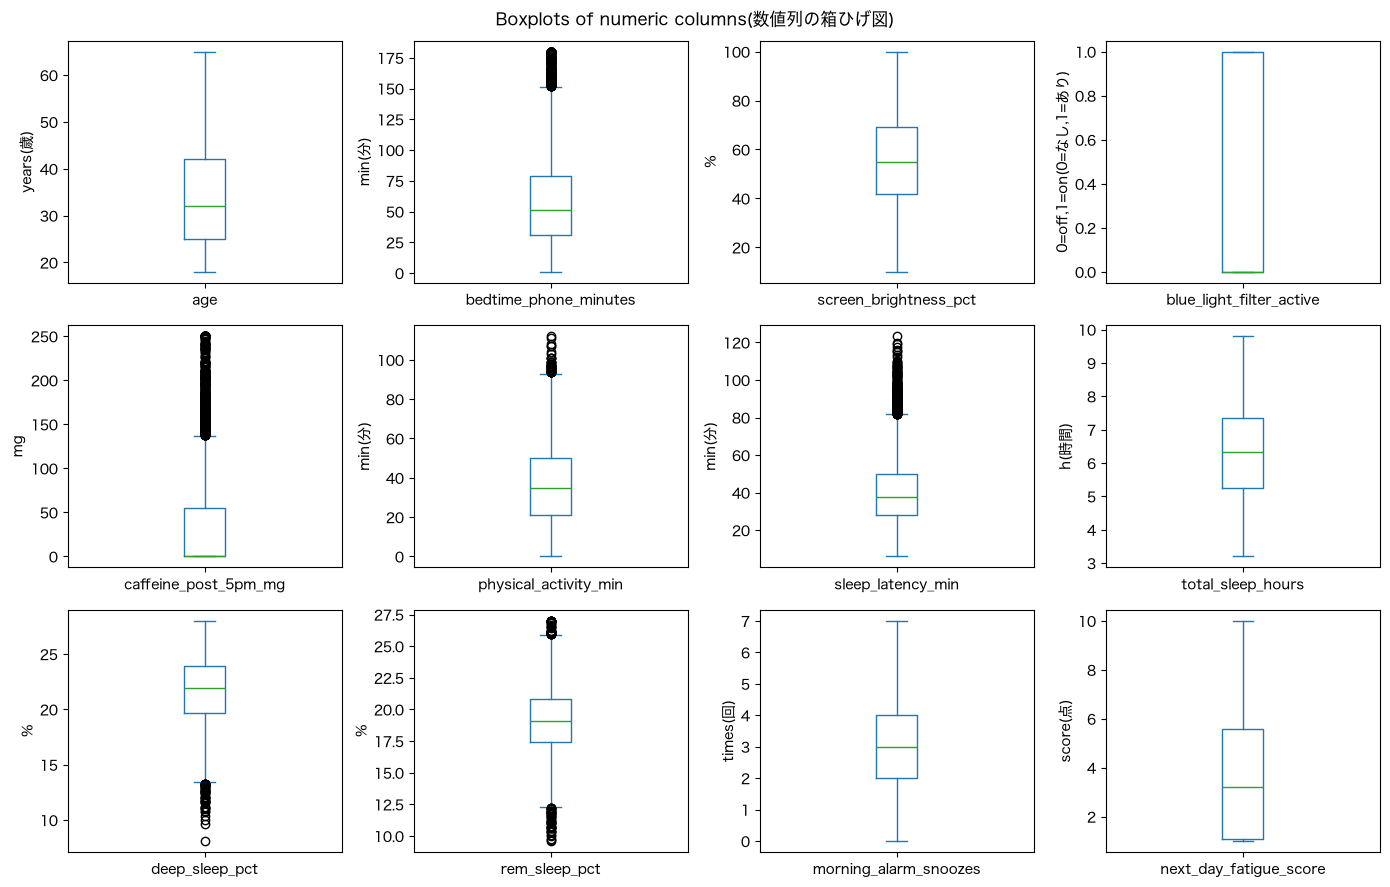

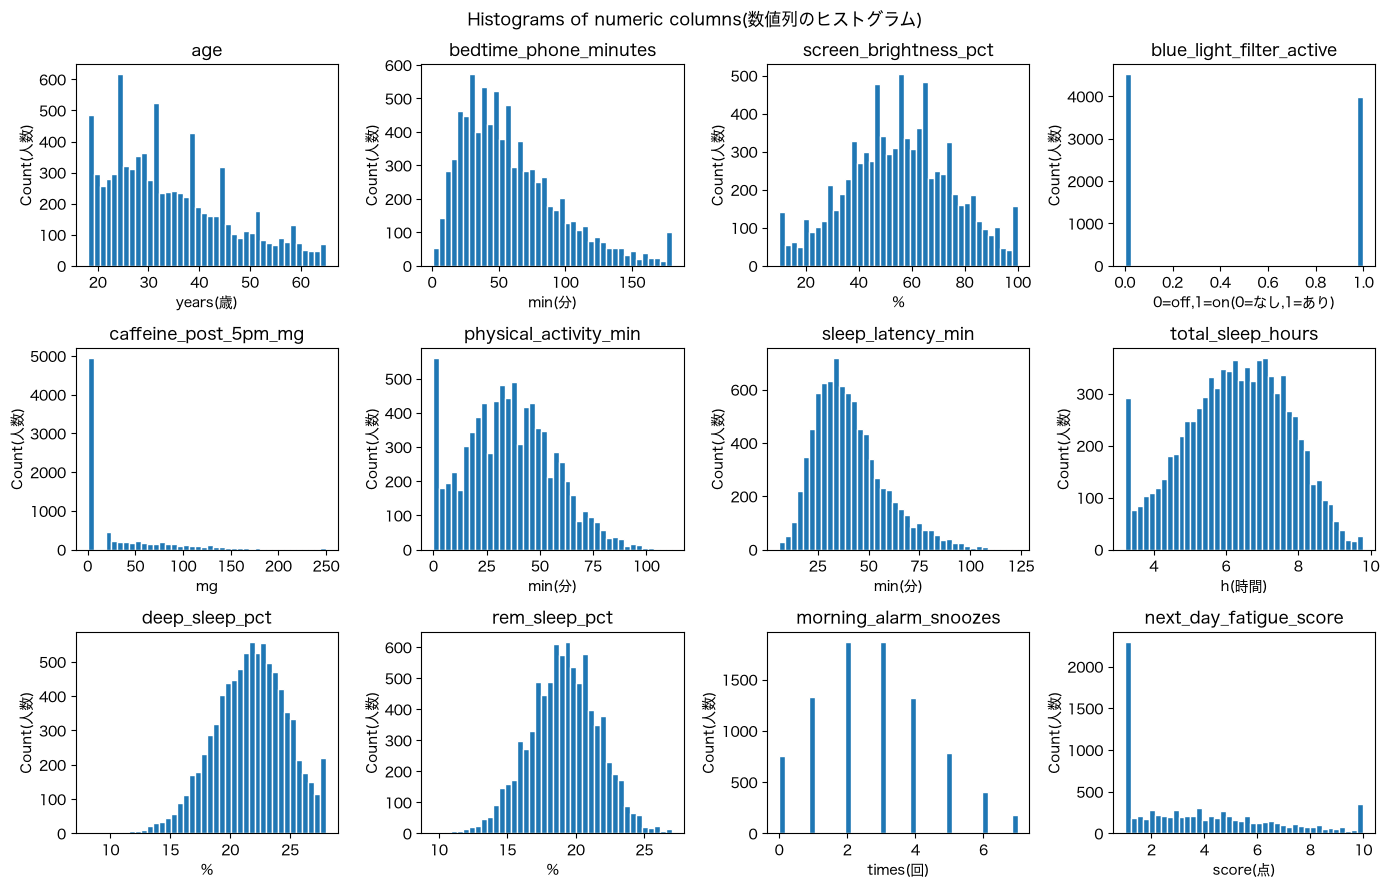

Correlation matrix(相関行列):
                            age  bedtime_phone_minutes  screen_brightness_pct  blue_light_filter_active  caffeine_post_5pm_mg  physical_activity_min  sleep_latency_min  total_sleep_hours  deep_sleep_pct  rem_sleep_pct  morning_alarm_snoozes  next_day_fatigue_score
age                       1.000                 -0.016                 -0.005                     0.004                -0.007                 -0.013             -0.055              0.016           0.011          0.070                 -0.026                  -0.028
bedtime_phone_minutes    -0.016                  1.000                  0.001                     0.001                -0.008                 -0.008              0.858             -0.554          -0.262         -0.009                  0.652                   0.711
screen_brightness_pct    -0.005                  0.001                  1.000                     0.007                 0.002                  0.001              0.093            

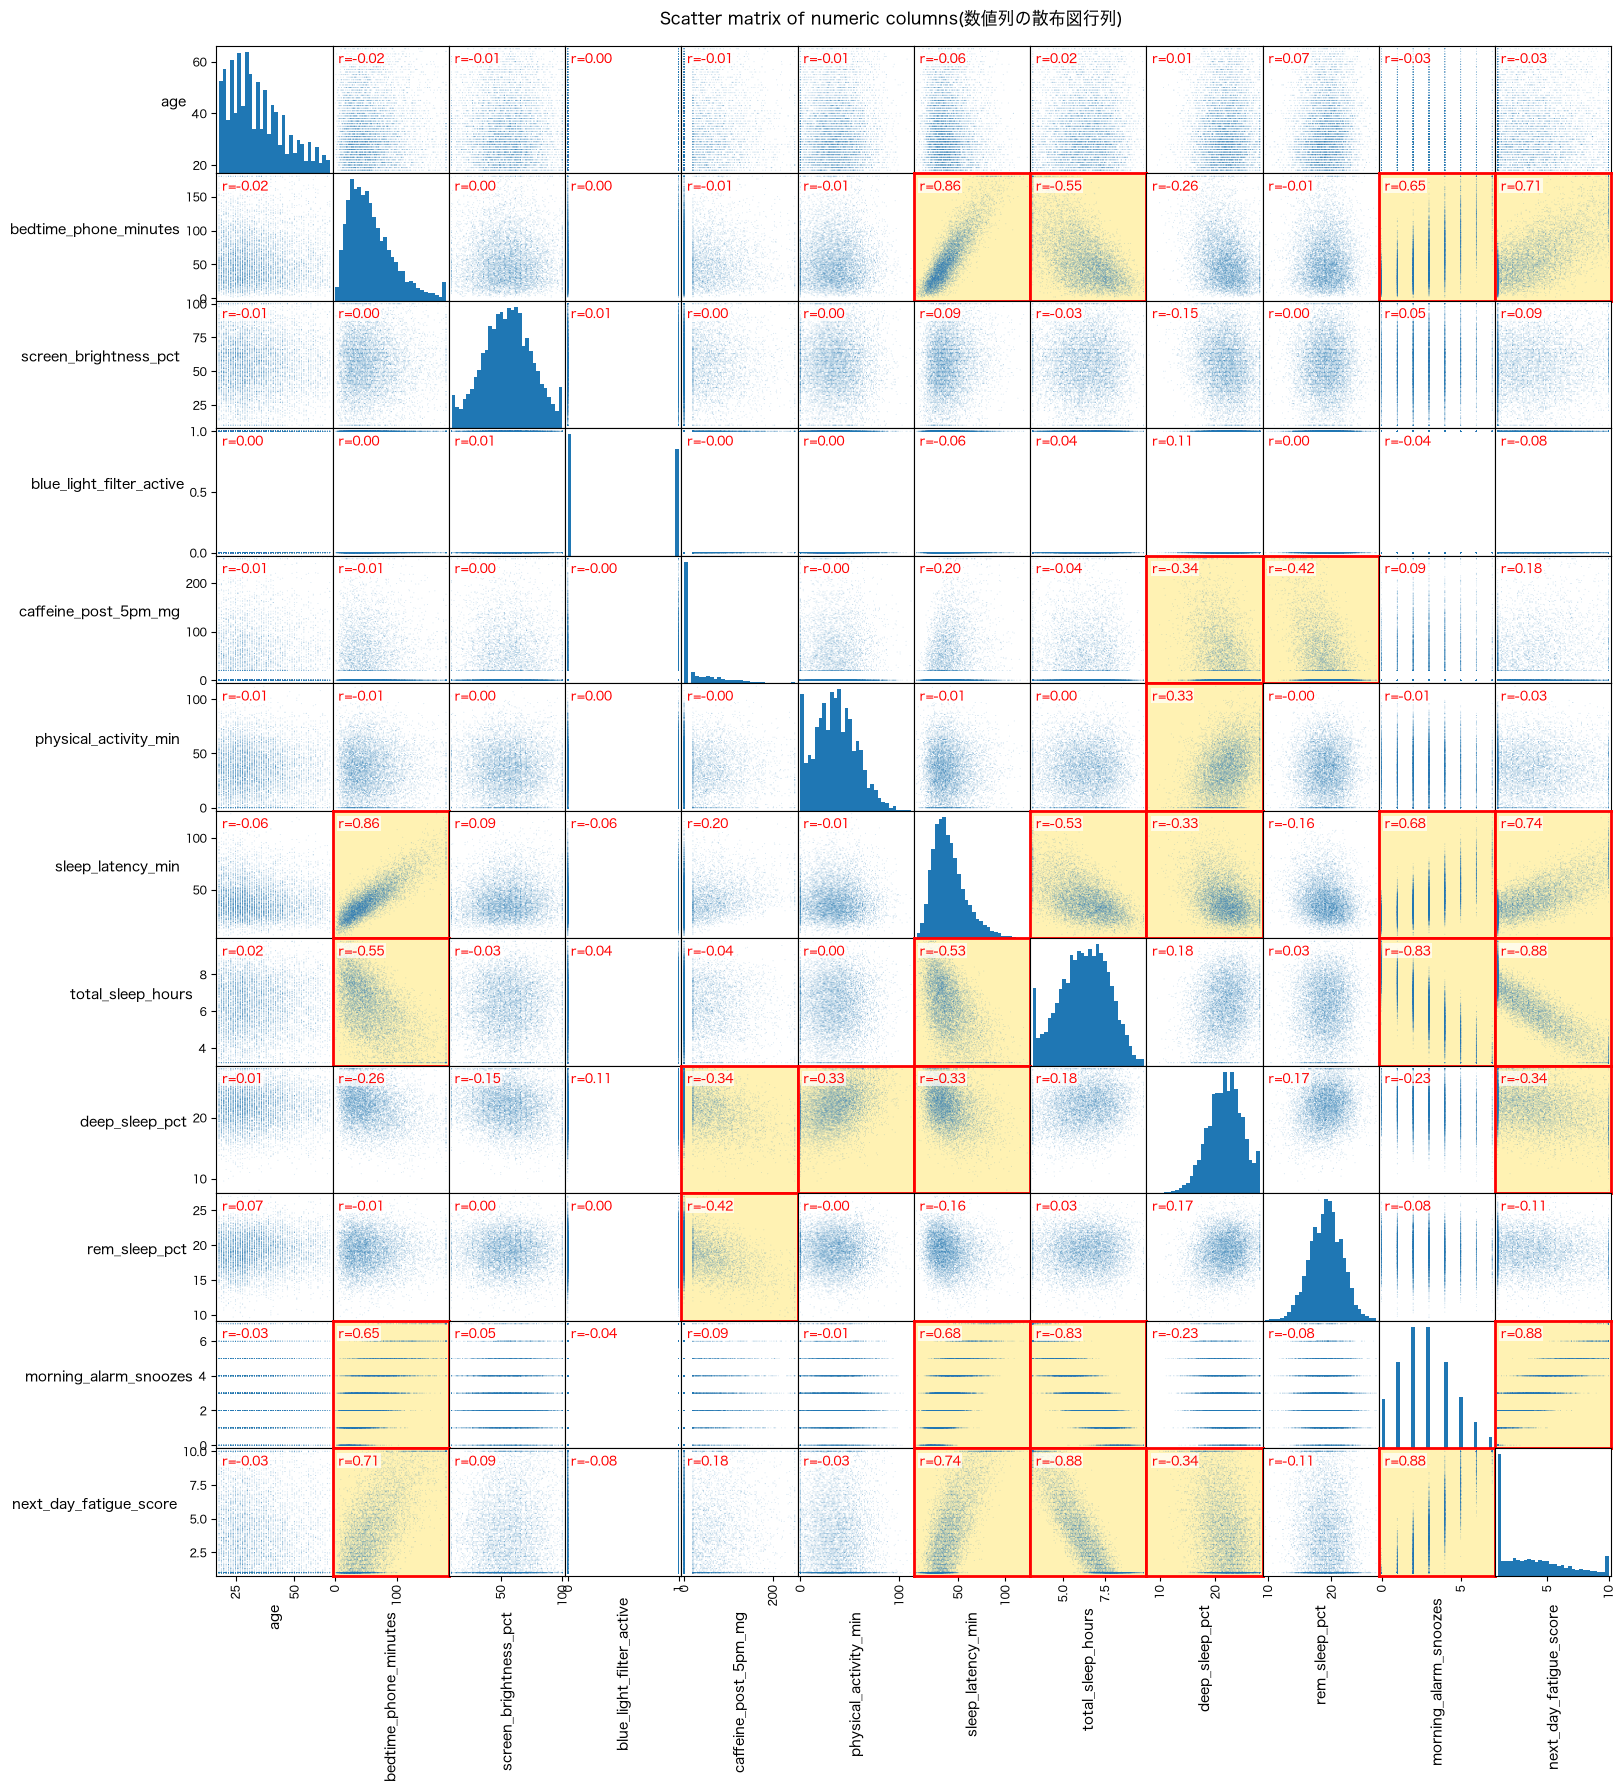

In [4]:
# 数値列の記述統計
print("Descriptive statistics(記述統計):")
print(df.describe().T.to_string())

num_cols = df.select_dtypes(include="number").columns

# 各列の単位
UNITS = {
    "age": "years(歳)",
    "bedtime_phone_minutes": "min(分)",
    "screen_brightness_pct": "%",
    "blue_light_filter_active": "0=off,1=on(0=なし,1=あり)",
    "caffeine_post_5pm_mg": "mg",
    "physical_activity_min": "min(分)",
    "sleep_latency_min": "min(分)",
    "total_sleep_hours": "h(時間)",
    "deep_sleep_pct": "%",
    "rem_sleep_pct": "%",
    "morning_alarm_snoozes": "times(回)",
    "next_day_fatigue_score": "score(点)",
}

# 数値列の箱ひげ図（単位が列ごとに違うので、列ごとに軸を分ける）
axes = df[num_cols].plot.box(subplots=True, layout=(3, 4), figsize=(14, 9), sharey=False)
for col in num_cols:
    axes[col].set_ylabel(UNITS[col])
plt.suptitle("Boxplots of numeric columns(数値列の箱ひげ図)")
plt.tight_layout()
plt.show()

# 数値列のヒストグラム
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, col in zip(axes.flatten(), num_cols):
    df[col].plot.hist(bins=40, ax=ax, edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel(UNITS[col])
    ax.set_ylabel("Count(人数)")
plt.suptitle("Histograms of numeric columns(数値列のヒストグラム)")
plt.tight_layout()
plt.show()

# 数値列どうしの相関係数（ピアソン）
corr = df[num_cols].corr()
print("Correlation matrix(相関行列):")
print(corr.round(3).to_string())

# 散布図行列（総当たりの散布図。対角はヒストグラム）
axes = pd.plotting.scatter_matrix(df[num_cols], figsize=(18, 18), s=2, alpha=0.2, hist_kwds={"bins": 30})
# 対角以外の各グラフに相関係数を書き、|r|が0.3を超える枠は背景色と太枠で強調する
CORR_THRESHOLD = 0.3
for i, row_col in enumerate(num_cols):
    for j, col_col in enumerate(num_cols):
        if i != j:
            if abs(corr.loc[row_col, col_col]) > CORR_THRESHOLD:
                axes[i, j].set_facecolor("#fff2b3")
                for spine in axes[i, j].spines.values():
                    spine.set_edgecolor("red")
                    spine.set_linewidth(2)
            axes[i, j].text(0.05, 0.95, f"r={corr.loc[row_col, col_col]:.2f}", transform=axes[i, j].transAxes,
                            fontsize=9, va="top", color="red", bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none", "pad": 1})
for ax in axes.flatten():
    ax.xaxis.label.set_rotation(90)
    ax.yaxis.label.set_rotation(0)
    ax.yaxis.label.set_horizontalalignment("right")
plt.subplots_adjust(top=0.96)
plt.suptitle("Scatter matrix of numeric columns(数値列の散布図行列)", y=0.98)
plt.show()

In [5]:
# カテゴリ列の内訳
cat_cols = df.select_dtypes(include="object").columns.drop("user_id")
for col in cat_cols:
    print(f"{col}(件数):")
    print(df[col].value_counts().to_string())
    print()

gender(件数):
gender
Female        4347
Male          3905
Non-Binary     248

occupation_type(件数):
occupation_type
Corporate 9-to-5             2838
Remote Tech                  2142
Student                      1622
Healthcare / Shift Worker     997
Freelance / Creative          901

chronotype(件数):
chronotype
Intermediate    3880
Night Owl       2455
Morning Lark    2165

primary_bedtime_app(件数):
primary_bedtime_app
TikTok / Reels              2198
YouTube                     1928
Instagram / Reddit          1630
Streaming (Netflix/Hulu)    1301
Messaging / Chat             847
News / Reading               596

sleep_debt_category(件数):
sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647



/var/folders/mm/_5w683_97v5d55mx3whv5c3c0000gn/T/ipykernel_59878/2387084741.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.drop("user_id")


Fatigue=10.0 count(疲労10.0の人数):314
Fatigue=10.0 ratio(疲労10.0の割合):0.0369
Fatigue=1.0 count(疲労1.0の人数):2110
Fatigue=1.0 ratio(疲労1.0の割合):0.2482
Sleep=3.2h count(睡眠3.2時間の人数):242
Sleep=9.8h count(睡眠9.8時間の人数):17

Fatigue at bounds by sleep group(睡眠時間グループ別の上限・下限の人数):
                       N(人数)  Fatigue=10.0(疲労10.0)  Fatigue=1.0(疲労1.0)  Ratio 10.0(10.0の割合)  Ratio 1.0(1.0の割合)
Sleep group(睡眠時間グループ)                                                                                         
-5h                     1713                   309                   0               0.1804             0.0000
5-6h                    1820                     5                   4               0.0027             0.0022
6-7h                    2097                     0                 186               0.0000             0.0887
7-8h                    1887                     0                 989               0.0000             0.5241
8h+                      983                     0                 931     

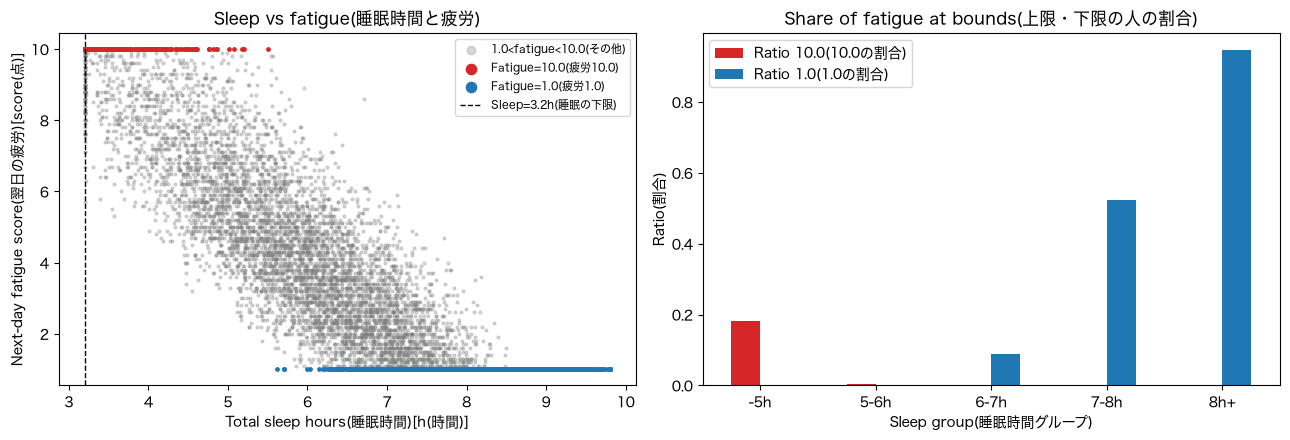

In [6]:
# 疲労スコアの上限10.0・下限1.0と、睡眠時間の上限・下限
TARGET = "next_day_fatigue_score"
SLEEP = "total_sleep_hours"
is_top = df[TARGET] == 10.0
is_bottom = df[TARGET] == 1.0
print(f"Fatigue=10.0 count(疲労10.0の人数):{is_top.sum()}")
print(f"Fatigue=10.0 ratio(疲労10.0の割合):{is_top.mean():.4f}")
print(f"Fatigue=1.0 count(疲労1.0の人数):{is_bottom.sum()}")
print(f"Fatigue=1.0 ratio(疲労1.0の割合):{is_bottom.mean():.4f}")
print(f"Sleep=3.2h count(睡眠3.2時間の人数):{(df[SLEEP] == 3.2).sum()}")
print(f"Sleep=9.8h count(睡眠9.8時間の人数):{(df[SLEEP] == 9.8).sum()}")
print()

# 睡眠時間グループごとの、上限・下限に張り付いた人数と割合
# 区切りは Step 4 の初期案と同じ1時間刻み（左閉じ・右開き）
bins = [0, 5, 6, 7, 8, 24]
labels = ["-5h", "5-6h", "6-7h", "7-8h", "8h+"]
sleep_bin = pd.cut(df[SLEEP], bins=bins, labels=labels, right=False)
bound_table = pd.DataFrame({
    "N(人数)": is_top.groupby(sleep_bin, observed=False).size(),
    "Fatigue=10.0(疲労10.0)": is_top.groupby(sleep_bin, observed=False).sum(),
    "Fatigue=1.0(疲労1.0)": is_bottom.groupby(sleep_bin, observed=False).sum(),
    "Ratio 10.0(10.0の割合)": is_top.groupby(sleep_bin, observed=False).mean().round(4),
    "Ratio 1.0(1.0の割合)": is_bottom.groupby(sleep_bin, observed=False).mean().round(4),
})
bound_table.index.name = "Sleep group(睡眠時間グループ)"
print("Fatigue at bounds by sleep group(睡眠時間グループ別の上限・下限の人数):")
print(bound_table.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 左：睡眠時間と疲労の散布図。上限・下限に張り付いた点を色分けする
is_mid = ~(is_top | is_bottom)
axes[0].scatter(df.loc[is_mid, SLEEP], df.loc[is_mid, TARGET], s=4, alpha=0.3, color="gray", label="1.0<fatigue<10.0(その他)")
axes[0].scatter(df.loc[is_top, SLEEP], df.loc[is_top, TARGET], s=6, color="tab:red", label="Fatigue=10.0(疲労10.0)")
axes[0].scatter(df.loc[is_bottom, SLEEP], df.loc[is_bottom, TARGET], s=6, color="tab:blue", label="Fatigue=1.0(疲労1.0)")
axes[0].axvline(3.2, color="black", linestyle="--", linewidth=1, label="Sleep=3.2h(睡眠の下限)")
axes[0].set_xlabel(f"Total sleep hours(睡眠時間)[{UNITS[SLEEP]}]")
axes[0].set_ylabel(f"Next-day fatigue score(翌日の疲労)[{UNITS[TARGET]}]")
axes[0].set_title("Sleep vs fatigue(睡眠時間と疲労)")
axes[0].legend(fontsize=8, markerscale=3)

# 右：グループごとの、上限・下限に張り付いた人の割合
bound_table[["Ratio 10.0(10.0の割合)", "Ratio 1.0(1.0の割合)"]].plot.bar(ax=axes[1], color=["tab:red", "tab:blue"], rot=0)
axes[1].set_xlabel("Sleep group(睡眠時間グループ)")
axes[1].set_ylabel("Ratio(割合)")
axes[1].set_title("Share of fatigue at bounds(上限・下限の人の割合)")

plt.tight_layout()
plt.show()

gender:
            N(人数)  Fatigue mean(疲労の平均)  Fatigue std(疲労の標準偏差)  Sleep mean(睡眠時間の平均)  Sleep std(睡眠時間の標準偏差)
gender                                                                                                 
Female       4347                3.795                 2.677                6.263                 1.445
Male         3905                3.798                 2.687                6.267                 1.442
Non-Binary    248                3.743                 2.796                6.306                 1.531

occupation_type:
                           N(人数)  Fatigue mean(疲労の平均)  Fatigue std(疲労の標準偏差)  Sleep mean(睡眠時間の平均)  Sleep std(睡眠時間の標準偏差)
occupation_type                                                                                                       
Corporate 9-to-5            2838                3.573                 2.598                6.430                 1.386
Freelance / Creative         901                3.675                 2.651                6.376 

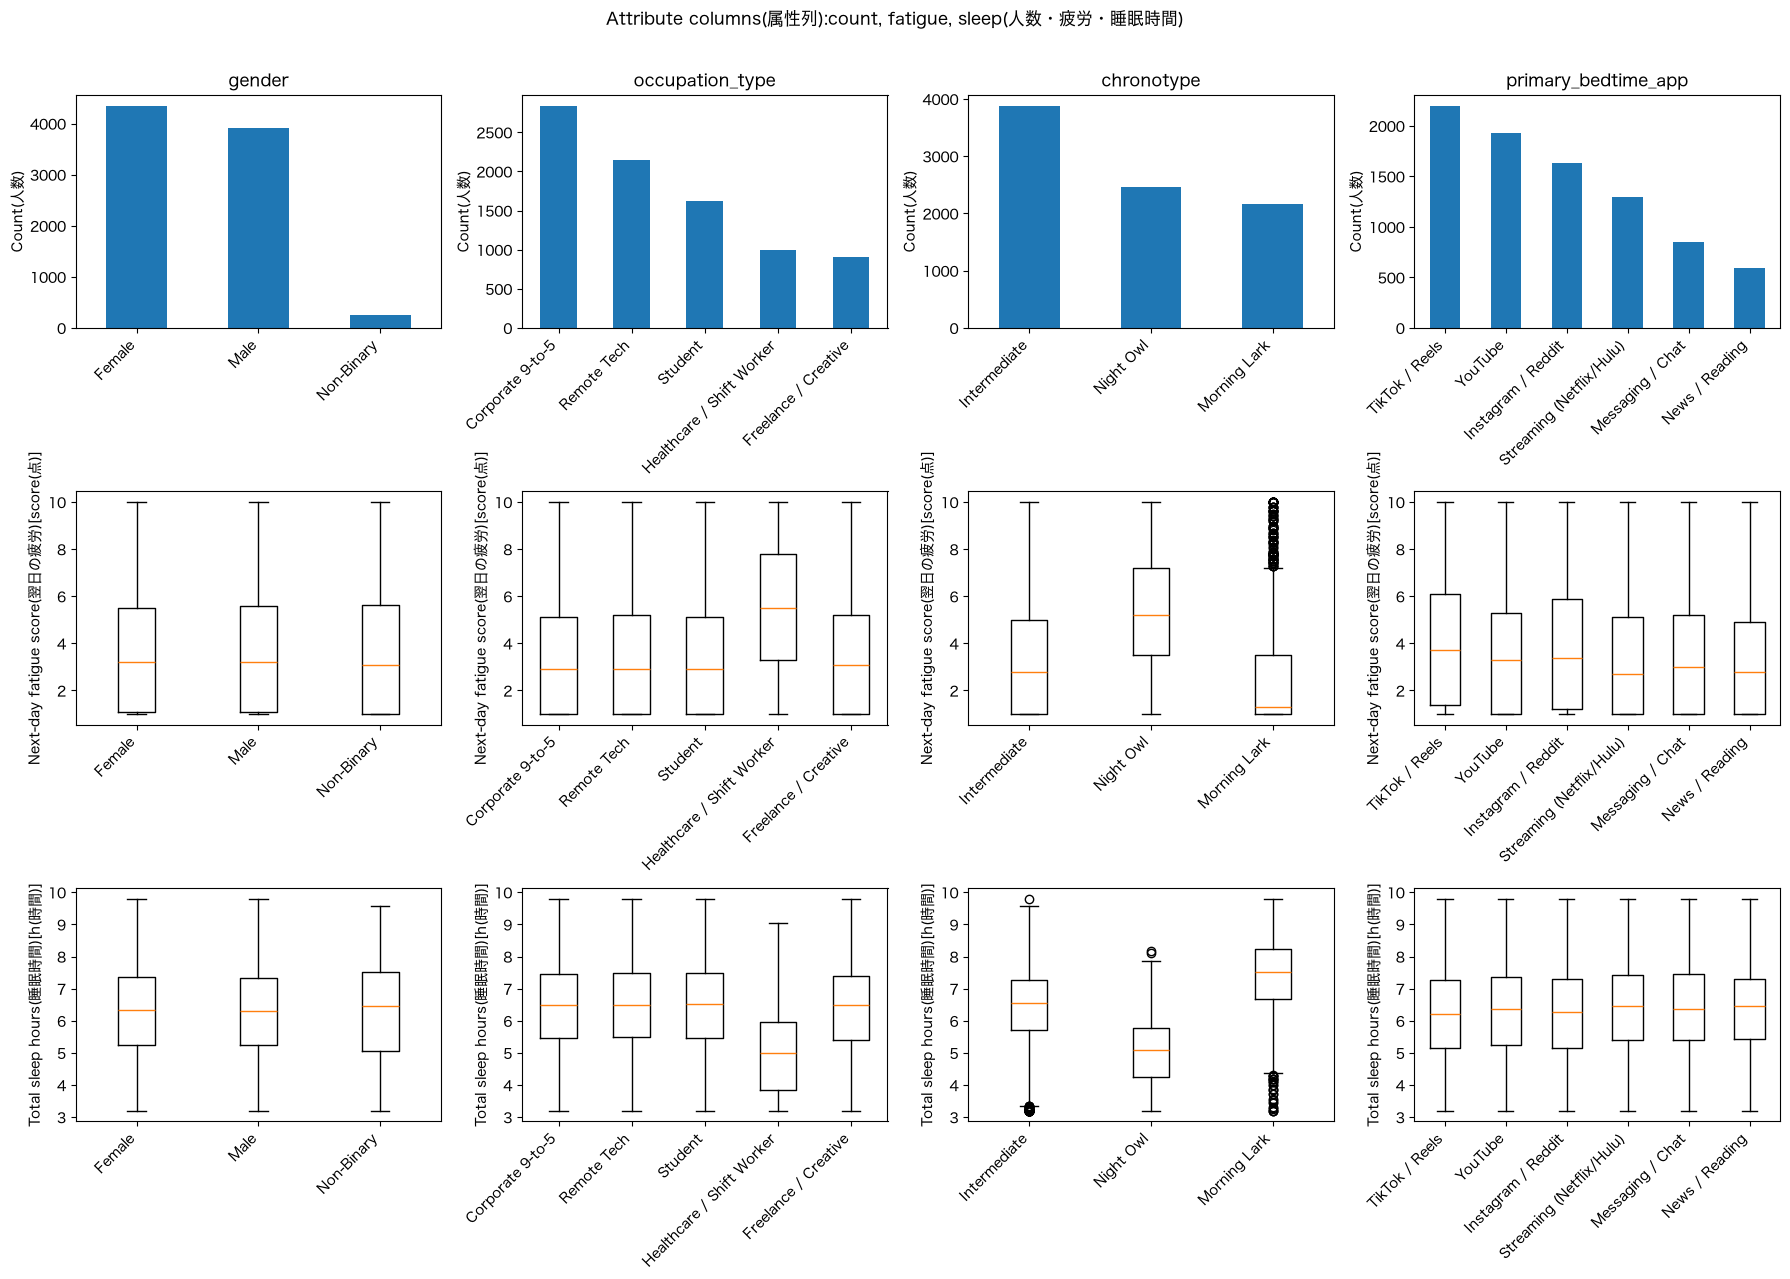

In [7]:
# 属性列（カテゴリ）ごとの人数、疲労、睡眠時間
# 年齢は数値列なので、上の箱ひげ図・ヒストグラム・散布図行列に含まれている
ATTR_COLS = ["gender", "occupation_type", "chronotype", "primary_bedtime_app"]
for col in ATTR_COLS:
    attr_table = df.groupby(col).agg(**{
        "N(人数)": (TARGET, "size"),
        "Fatigue mean(疲労の平均)": (TARGET, "mean"),
        "Fatigue std(疲労の標準偏差)": (TARGET, "std"),
        "Sleep mean(睡眠時間の平均)": (SLEEP, "mean"),
        "Sleep std(睡眠時間の標準偏差)": (SLEEP, "std"),
    }).round(3)
    print(f"{col}:")
    print(attr_table.to_string())
    print()

# 1行目：人数、2行目：疲労の箱ひげ図、3行目：睡眠時間の箱ひげ図
fig, axes = plt.subplots(3, len(ATTR_COLS), figsize=(18, 13))
for j, col in enumerate(ATTR_COLS):
    order = df[col].value_counts().index
    df[col].value_counts().plot.bar(ax=axes[0, j], rot=45)
    axes[0, j].set_title(col)
    axes[0, j].set_xlabel("")
    axes[0, j].set_ylabel("Count(人数)")
    for k, (y_col, y_label) in enumerate([(TARGET, "Next-day fatigue score(翌日の疲労)"), (SLEEP, "Total sleep hours(睡眠時間)")], start=1):
        axes[k, j].boxplot([df.loc[df[col] == v, y_col] for v in order], tick_labels=order)
        axes[k, j].tick_params(axis="x", rotation=45)
        axes[k, j].set_ylabel(f"{y_label}[{UNITS[y_col]}]")
for ax in axes.flatten():
    plt.setp(ax.get_xticklabels(), ha="right")
plt.suptitle("Attribute columns(属性列):count, fatigue, sleep(人数・疲労・睡眠時間)")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [8]:
# 属性列のカテゴリごとの平均、箱ひげ図、ヒストグラムを出す関数
def describe_by_attr(attr_col, categories=None):
    if categories is None:
        categories = df[attr_col].value_counts().index.tolist()
    colors = {c: plt.cm.tab10(i) for i, c in enumerate(categories)}
    sub = df[df[attr_col].isin(categories)]

    # カテゴリ別の平均と、カテゴリ間の幅（最大 - 最小）
    means = sub.groupby(attr_col)[num_cols].mean().T[categories]
    means["Range(幅:最大-最小)"] = means[categories].max(axis=1) - means[categories].min(axis=1)
    print(f"Mean by {attr_col}({attr_col}別の平均):")
    print(means.round(3).to_string())

    # 箱ひげ図：列ごとにカテゴリを並べる
    fig, axes = plt.subplots(3, 4, figsize=(16, 11))
    for ax, col in zip(axes.flatten(), num_cols):
        bp = ax.boxplot([sub.loc[sub[attr_col] == c, col] for c in categories], tick_labels=categories, patch_artist=True)
        for patch, c in zip(bp["boxes"], categories):
            patch.set_facecolor(colors[c])
            patch.set_alpha(0.5)
        ax.set_title(col)
        ax.set_ylabel(UNITS[col])
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.suptitle(f"Boxplots by {attr_col}({attr_col}別の箱ひげ図)")
    plt.tight_layout()
    plt.show()

    # ヒストグラム：人数が違うので密度で、半透明にして重ねる
    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    for ax, col in zip(axes.flatten(), num_cols):
        for c in categories:
            sub.loc[sub[attr_col] == c, col].plot.hist(bins=40, ax=ax, density=True, alpha=0.4, color=colors[c], label=c)
        ax.set_title(col)
        ax.set_xlabel(UNITS[col])
        ax.set_ylabel("Density(密度)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="center right")
    plt.suptitle(f"Histograms by {attr_col}({attr_col}別のヒストグラム)")
    plt.tight_layout(rect=[0, 0, 0.88, 1])
    plt.show()

Mean by gender(gender別の平均):
gender                      Male  Female  Range(幅:最大-最小)
age                       34.414  34.317           0.098
bedtime_phone_minutes     59.214  59.242           0.028
screen_brightness_pct     55.099  55.157           0.058
blue_light_filter_active   0.474   0.463           0.011
caffeine_post_5pm_mg      33.849  32.925           0.923
physical_activity_min     35.397  35.997           0.600
sleep_latency_min         40.721  40.666           0.055
total_sleep_hours          6.267   6.263           0.004
deep_sleep_pct            21.737  21.736           0.001
rem_sleep_pct             19.075  19.110           0.035
morning_alarm_snoozes      2.766   2.767           0.001
next_day_fatigue_score     3.798   3.795           0.003


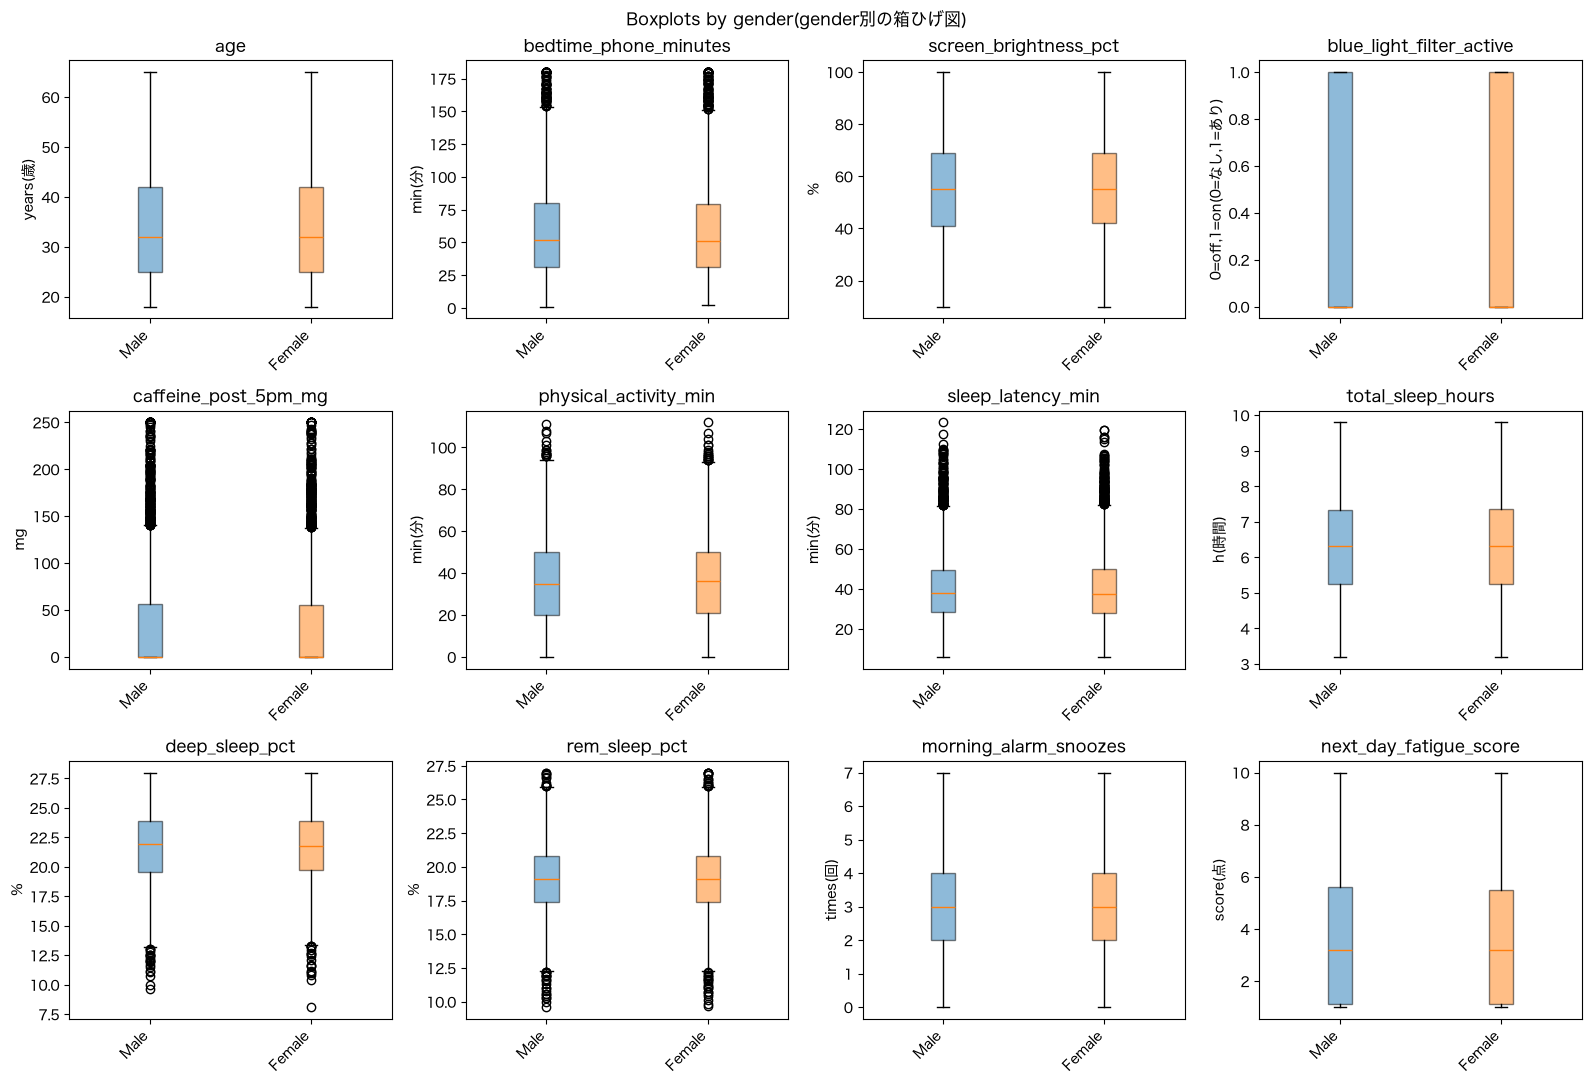

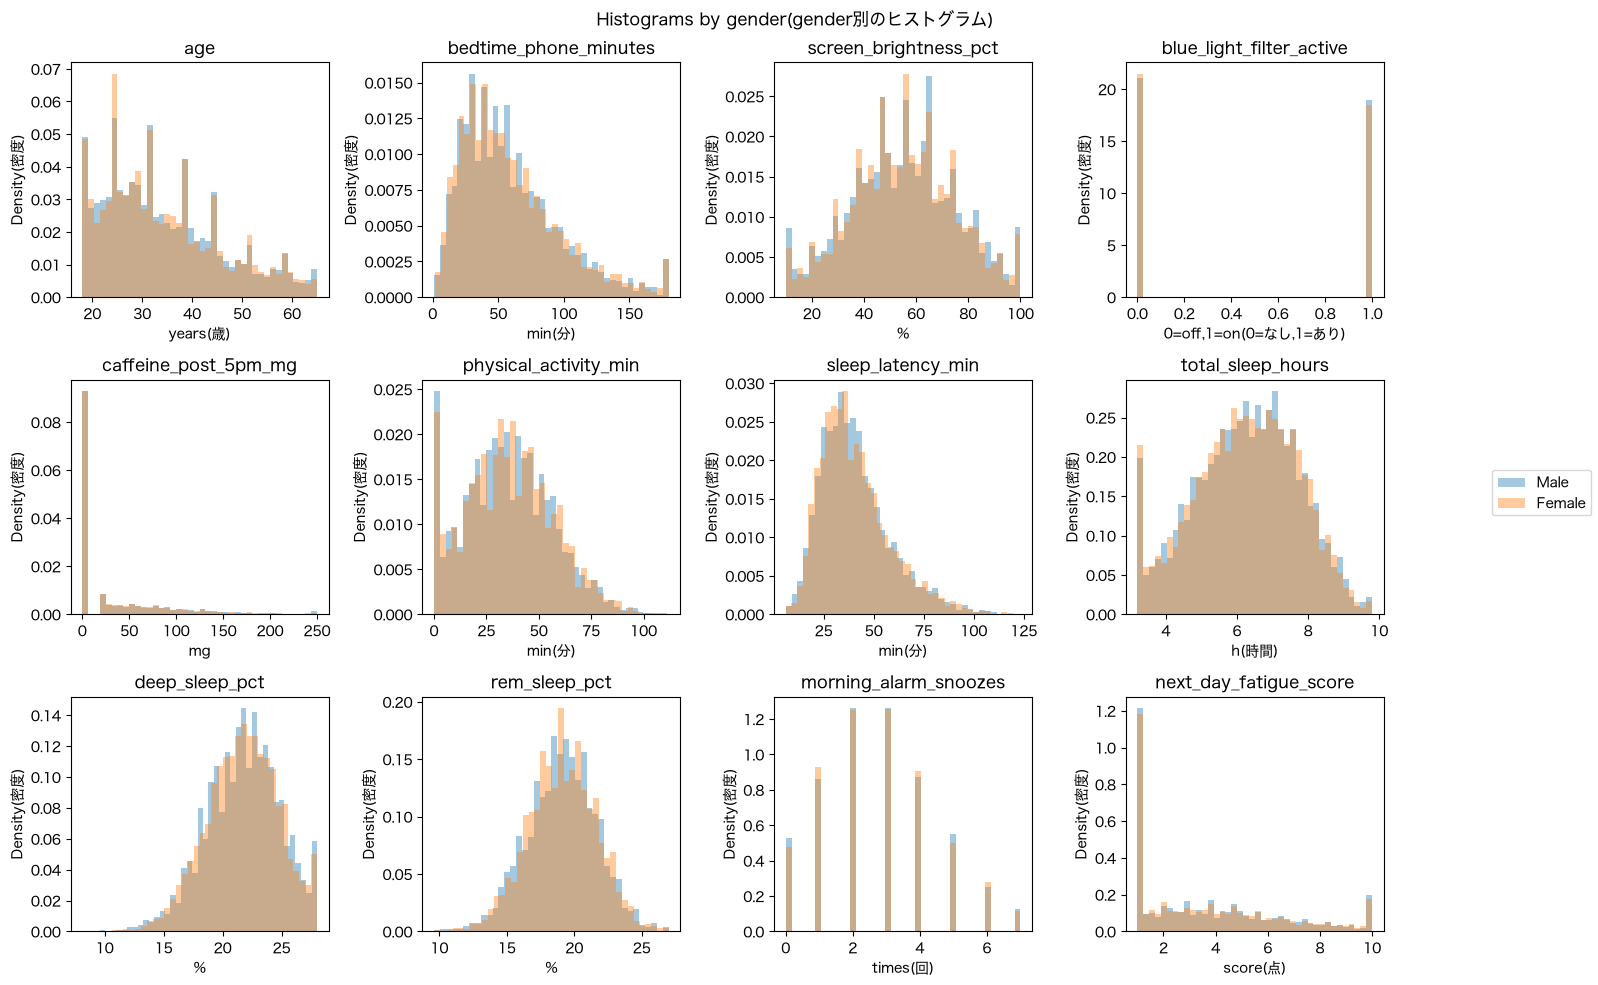

In [9]:
# 性別：男性・女性（ノンバイナリーは248人と少ないので除く）
describe_by_attr("gender", categories=["Male", "Female"])

Mean by occupation_type(occupation_type別の平均):
occupation_type           Corporate 9-to-5  Remote Tech  Student  Healthcare / Shift Worker  Freelance / Creative  Range(幅:最大-最小)
age                                 34.109       34.570   34.247                     34.316                34.863           0.754
bedtime_phone_minutes               59.070       59.404   58.892                     59.297                60.042           1.150
screen_brightness_pct               54.628       55.576   55.189                     55.962                54.850           1.334
blue_light_filter_active             0.383        0.592    0.582                      0.360                 0.354           0.237
caffeine_post_5pm_mg                32.785       33.734   32.213                     33.720                34.650           2.438
physical_activity_min               35.296       35.612   35.769                     35.454                37.344           2.048
sleep_latency_min                   40.834  

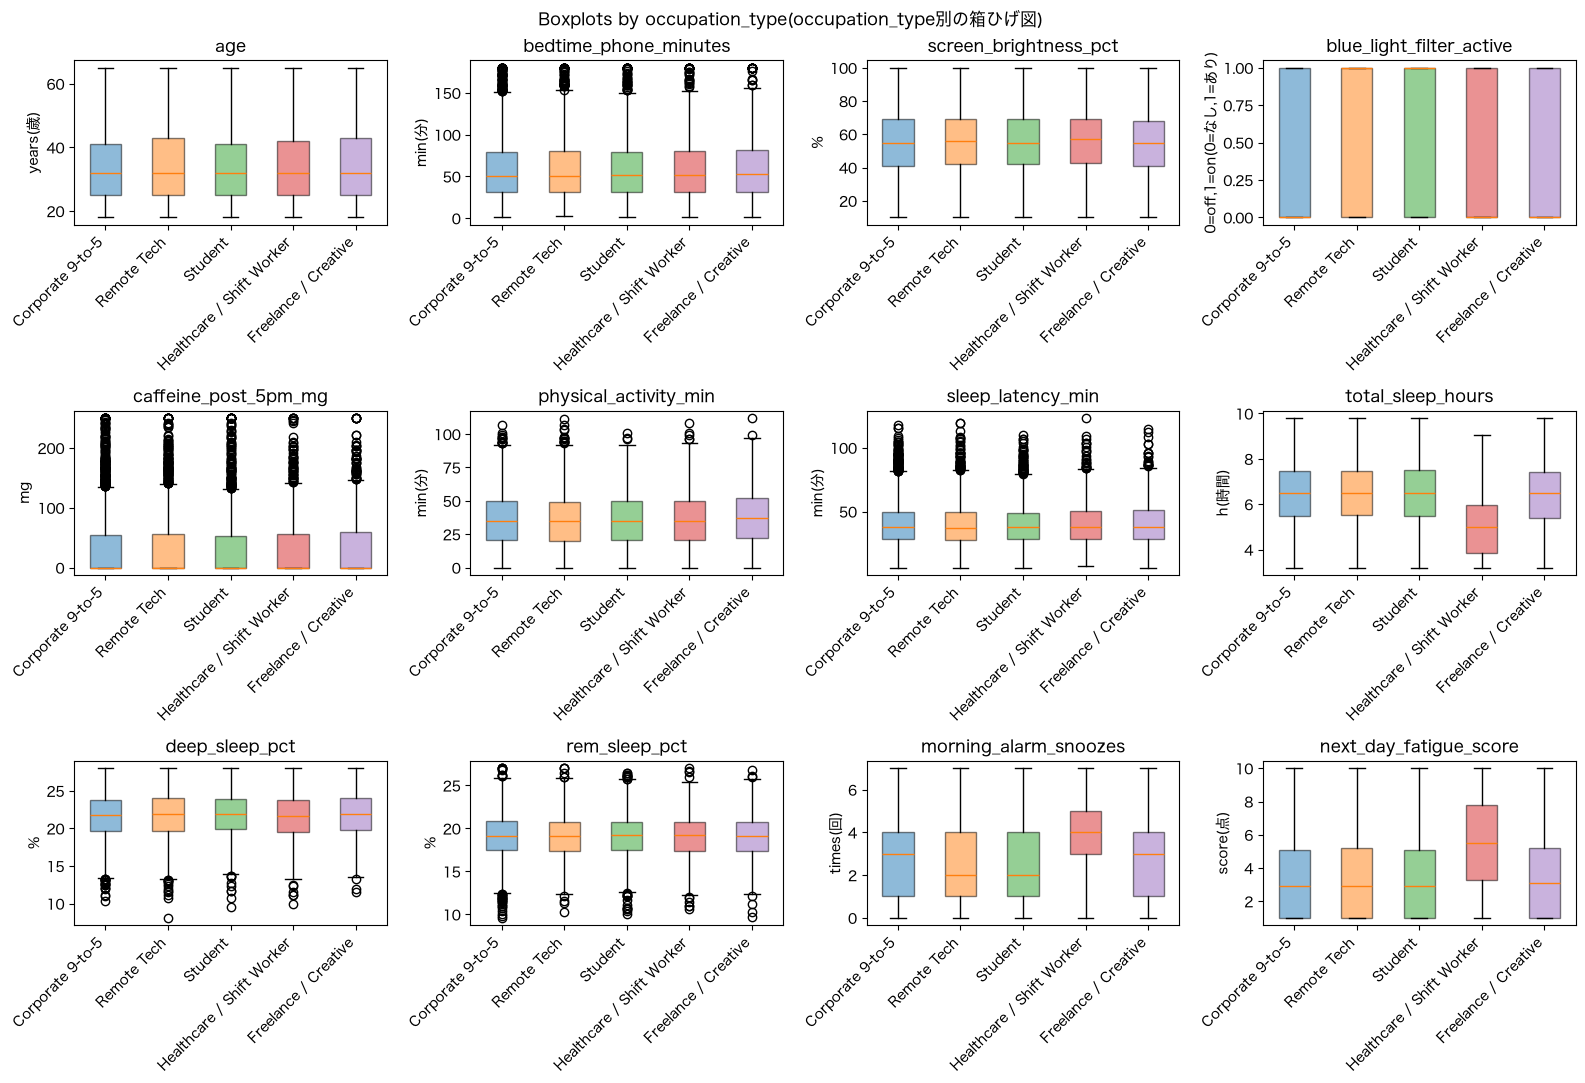

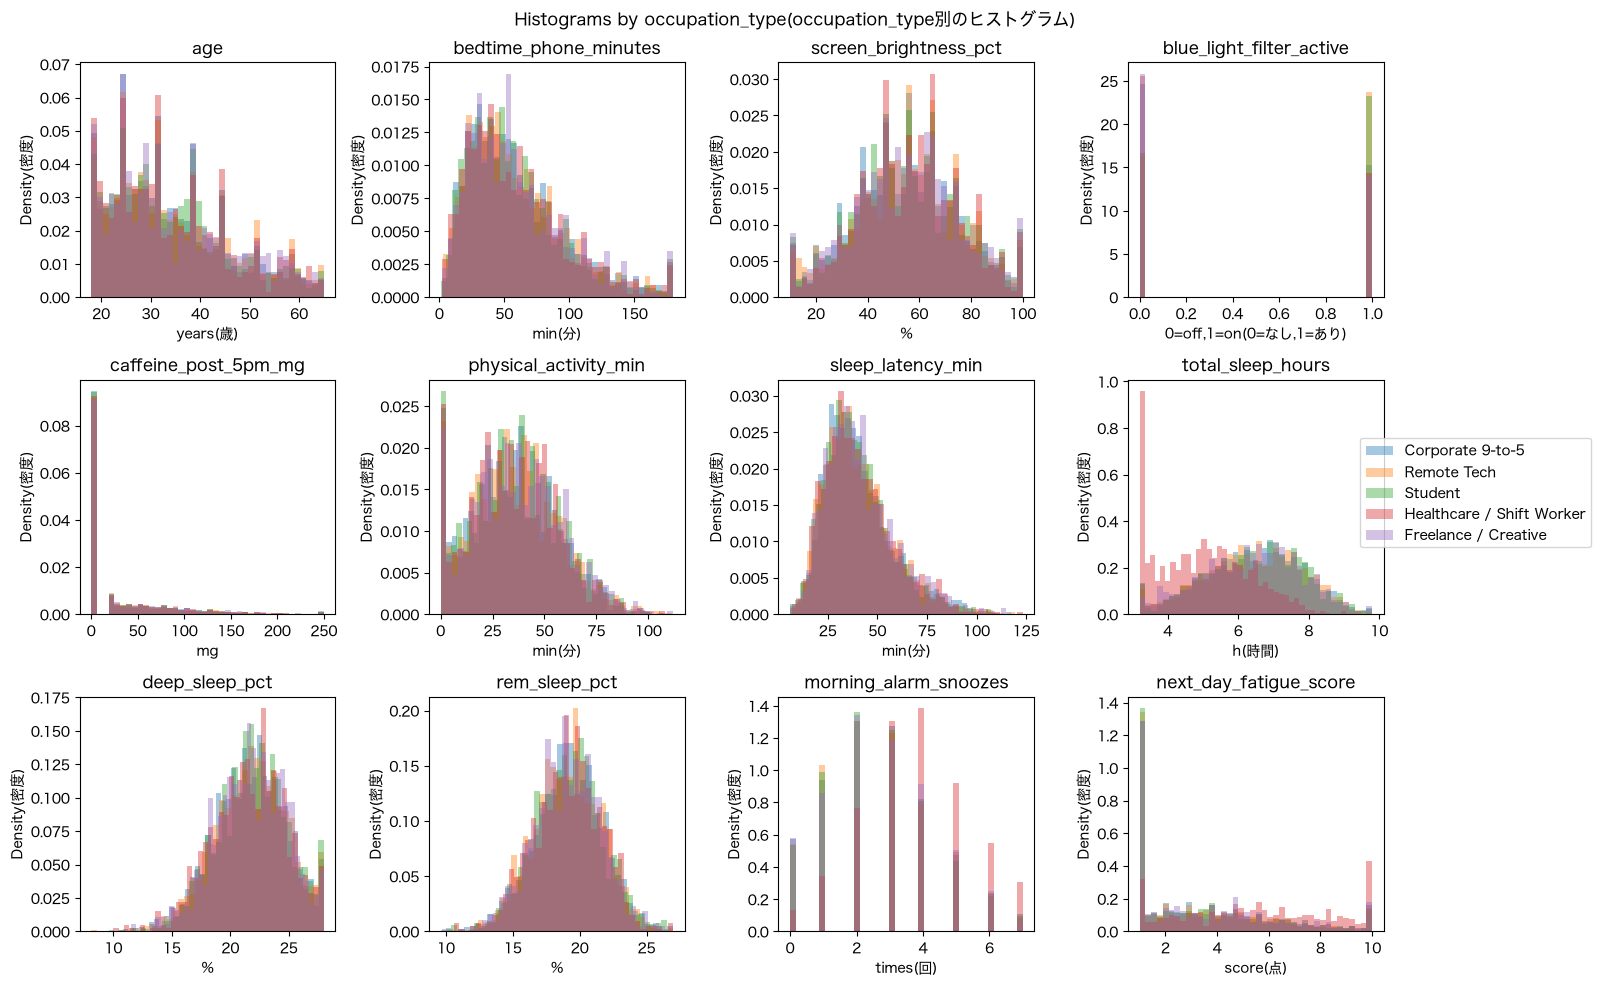

In [10]:
# 職業
describe_by_attr("occupation_type")

Mean by chronotype(chronotype別の平均):
chronotype                Intermediate  Night Owl  Morning Lark  Range(幅:最大-最小)
age                             34.418     34.438        34.150           0.288
bedtime_phone_minutes           59.565     58.307        59.755           1.448
screen_brightness_pct           55.514     54.970        54.717           0.796
blue_light_filter_active         0.461      0.475         0.471           0.014
caffeine_post_5pm_mg            32.623     33.380        34.118           1.495
physical_activity_min           35.368     35.827        36.157           0.789
sleep_latency_min               40.833     40.219        40.895           0.676
total_sleep_hours                6.438      5.012         7.381           2.370
deep_sleep_pct                  21.749     21.719        21.731           0.030
rem_sleep_pct                   19.112     19.126        19.071           0.055
morning_alarm_snoozes            2.613      3.731         1.945           1.786
next

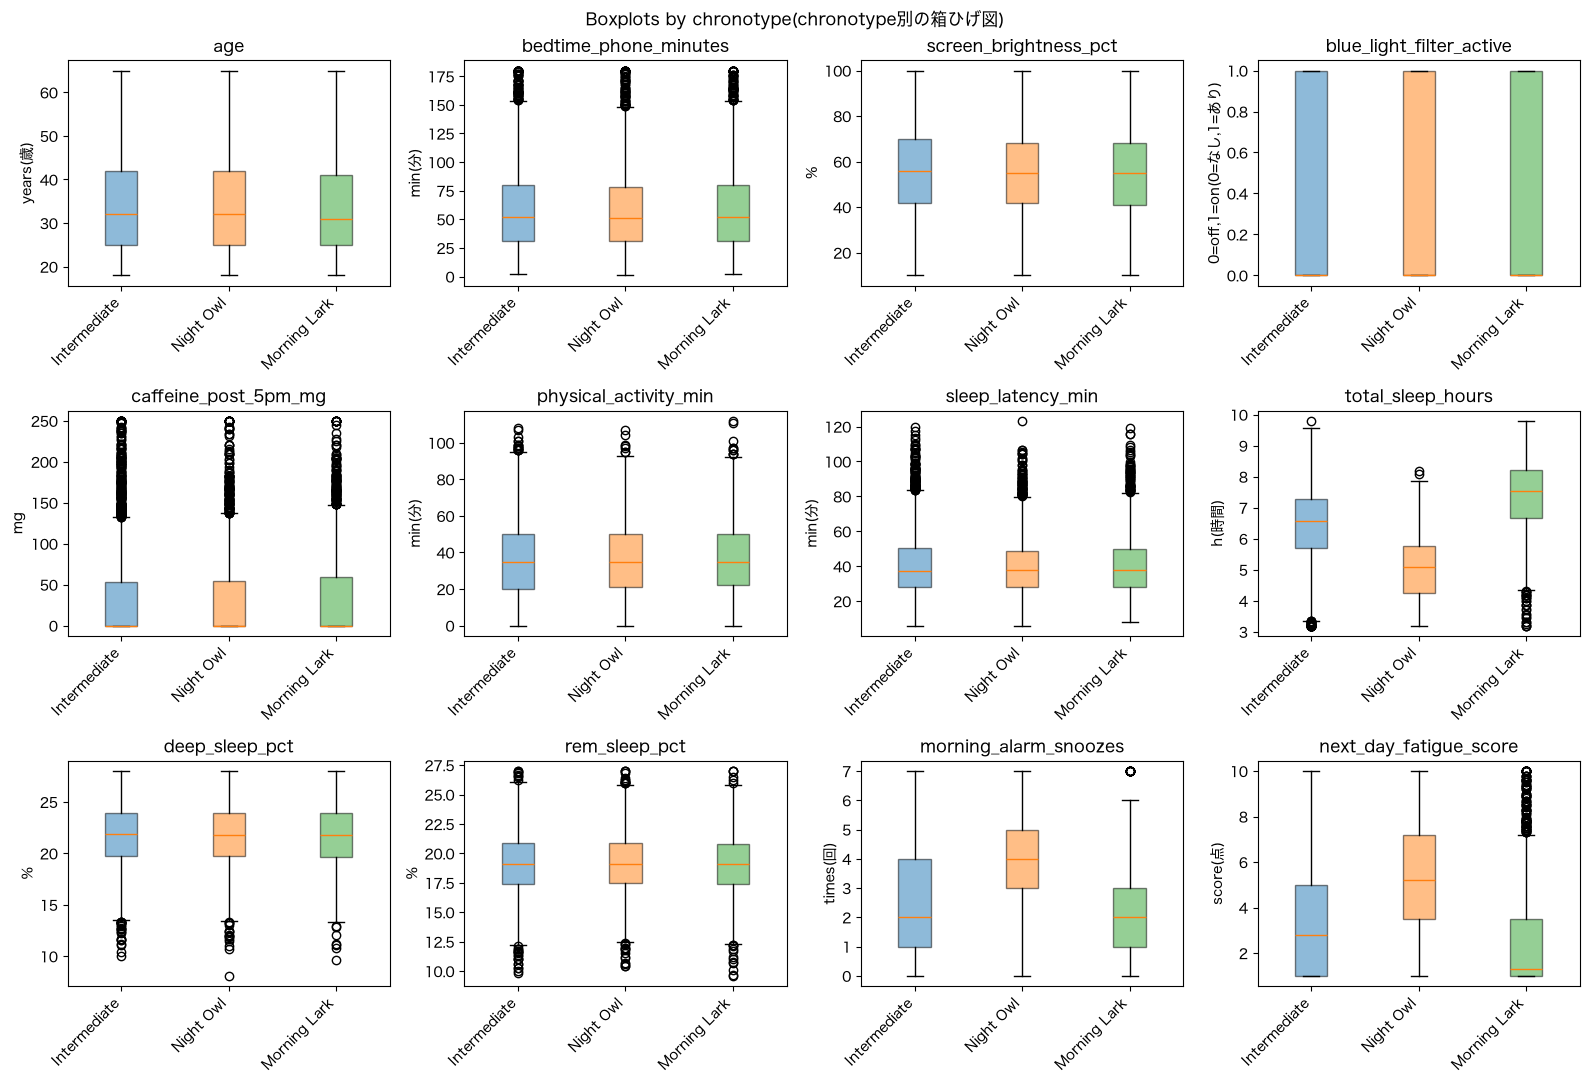

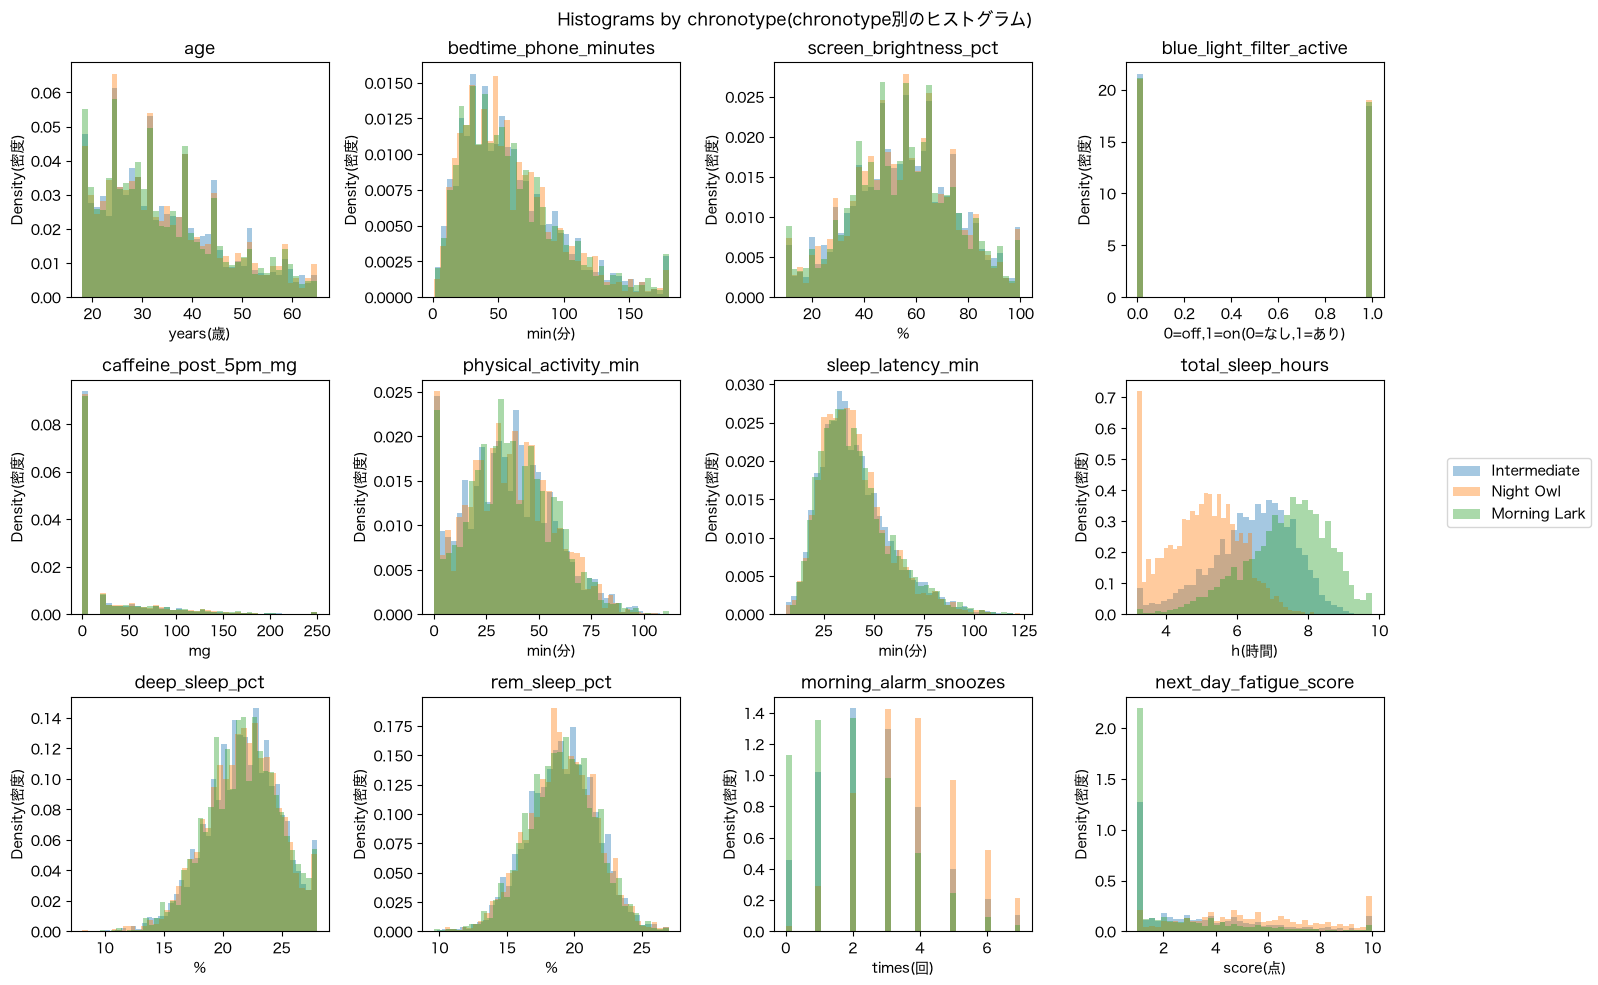

In [11]:
# クロノタイプ（朝型・夜型）
describe_by_attr("chronotype")

Mean by primary_bedtime_app(primary_bedtime_app別の平均):
primary_bedtime_app       TikTok / Reels  YouTube  Instagram / Reddit  Streaming (Netflix/Hulu)  Messaging / Chat  News / Reading  Range(幅:最大-最小)
age                               31.097   34.367              33.929                    37.141            36.765          38.002           6.905
bedtime_phone_minutes             59.853   58.290              60.858                    57.115            59.464          60.092           3.743
screen_brightness_pct             54.840   55.168              55.319                    55.397            54.797          55.794           0.997
blue_light_filter_active           0.465    0.449               0.487                     0.470             0.476           0.471           0.038
caffeine_post_5pm_mg              32.372   35.070              32.334                    33.248            31.757          34.842           3.313
physical_activity_min             35.201   36.113              35.648 

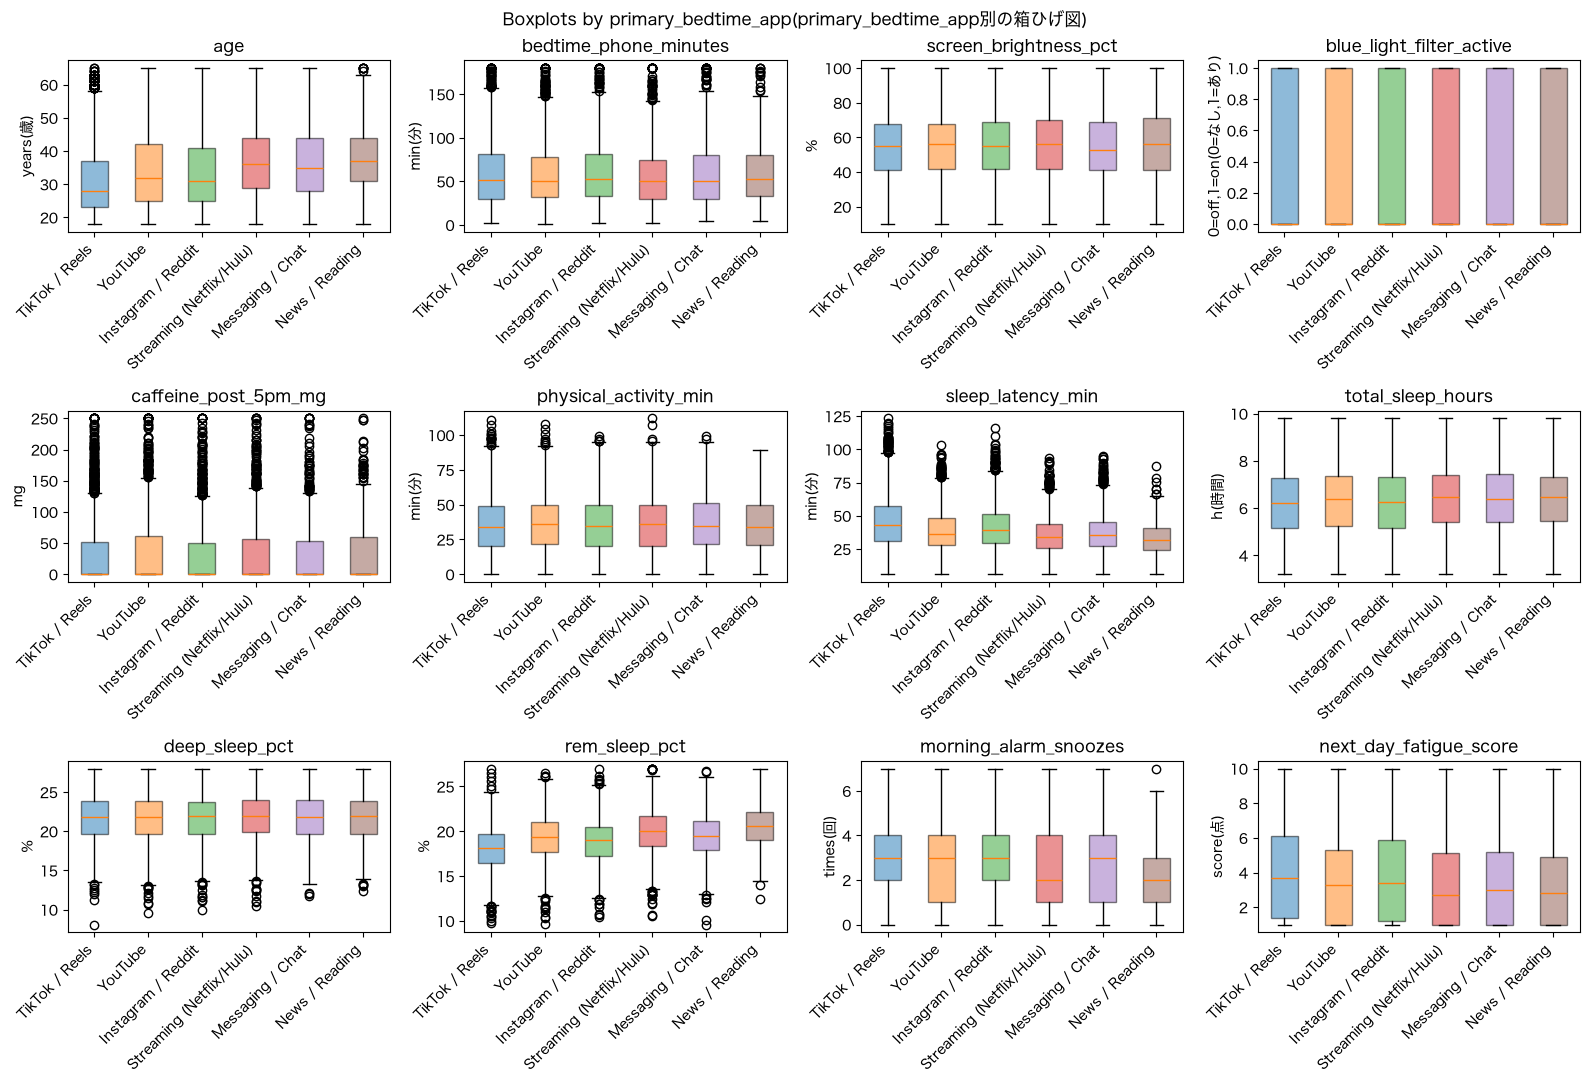

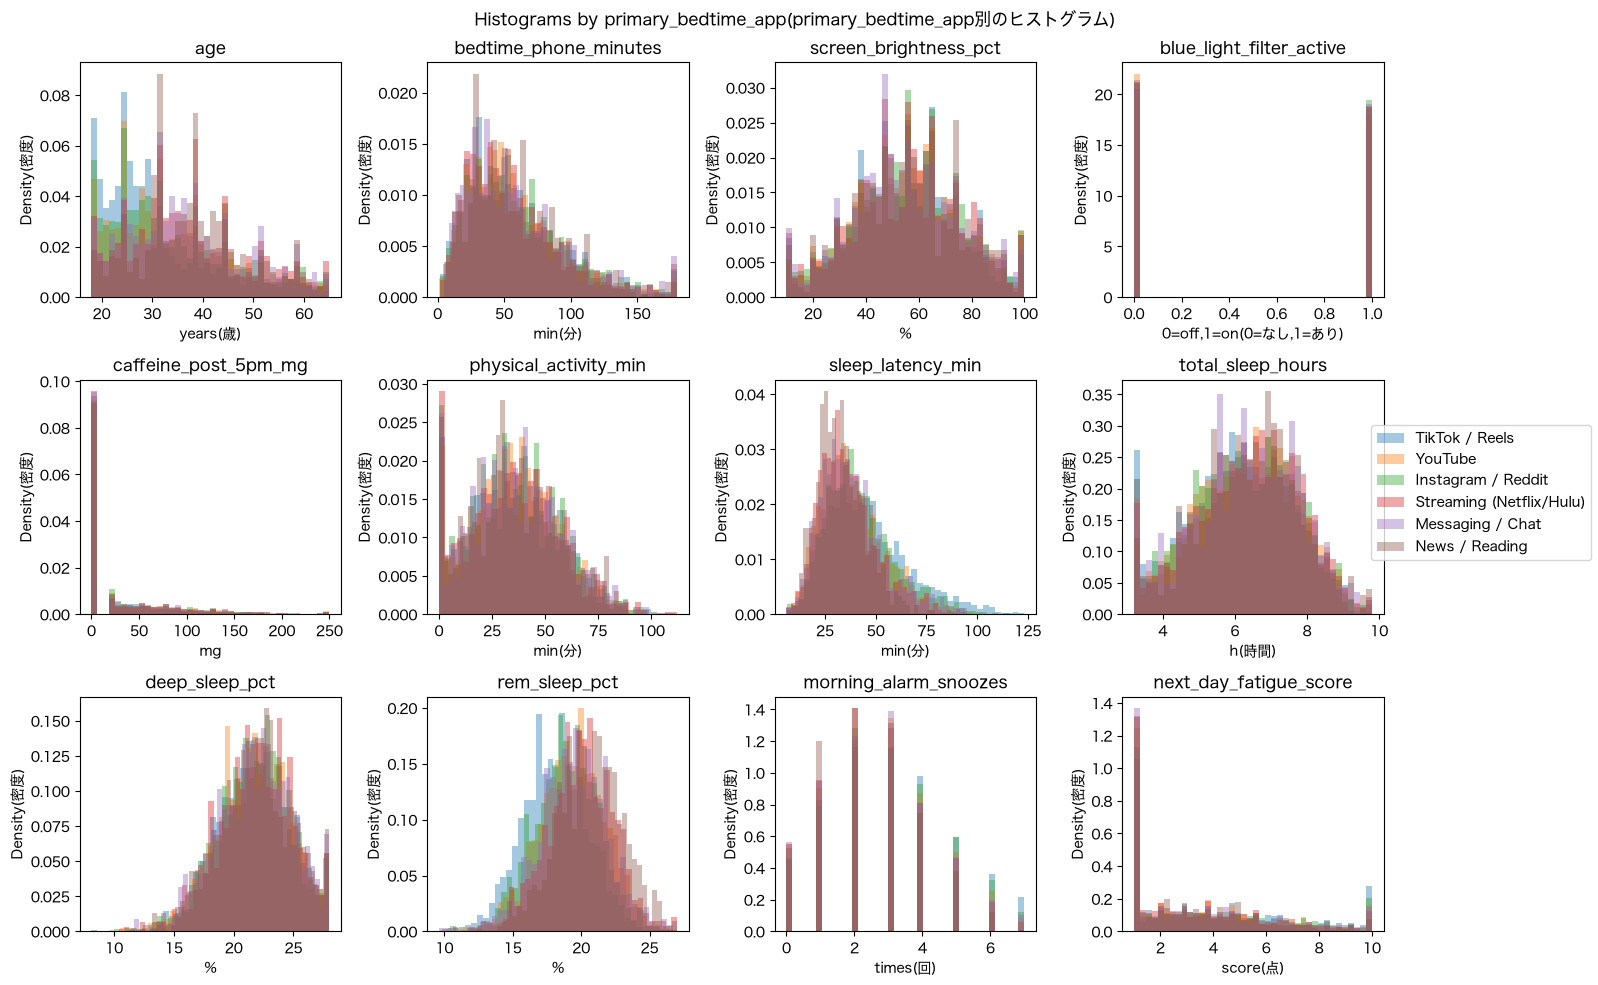

In [12]:
# 寝る前に使うアプリ
describe_by_attr("primary_bedtime_app")

## Step 3:Preprocessing(前処理)

- Missing values and duplicates(欠損値と重複):none(なし)
- Outliers(外れ値):kept as is(そのまま残す)
- Values at bounds(上限・下限への張り付き):kept as is(そのまま残す)
- Correlated features(相関の強い特徴量):kept as is, revisited in linear regression(そのまま残し、線形回帰で再検討)
- Scaling(標準化):done after the train/test split(学習とテストに分けた後で行う)

In [13]:
# 特徴量10個と目的変数を取り出す
# user_id はID、sleep_debt_category は睡眠時間から作られた列（答えの混入）なので除く
# 属性列（年齢・性別・職業・chronotype・アプリ）は使わない
FEATURES = [
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "blue_light_filter_active",
    "caffeine_post_5pm_mg",
    "physical_activity_min",
    "sleep_latency_min",
    "total_sleep_hours",
    "deep_sleep_pct",
    "rem_sleep_pct",
    "morning_alarm_snoozes",
]
X = df[FEATURES]
y = df[TARGET]

print(f"X rows(特徴量の行数):{X.shape[0]}")
print(f"X columns(特徴量の列数):{X.shape[1]}")
print(f"y rows(目的変数の行数):{y.shape[0]}")
print(f"Target(目的変数):{TARGET}")
print("Features(特徴量):")
for i, col in enumerate(FEATURES, start=1):
    print(f"{i}.{col}")
print("Dropped columns(除いた列):")
for col in df.columns.drop(FEATURES + [TARGET]):
    print(f"-{col}")

X rows(特徴量の行数):8500
X columns(特徴量の列数):10
y rows(目的変数の行数):8500
Target(目的変数):next_day_fatigue_score
Features(特徴量):
1.bedtime_phone_minutes
2.screen_brightness_pct
3.blue_light_filter_active
4.caffeine_post_5pm_mg
5.physical_activity_min
6.sleep_latency_min
7.total_sleep_hours
8.deep_sleep_pct
9.rem_sleep_pct
10.morning_alarm_snoozes
Dropped columns(除いた列):
-user_id
-age
-gender
-occupation_type
-chronotype
-primary_bedtime_app
-sleep_debt_category


## Step 4:Grouping by sleep duration(睡眠時間でグループに分ける)

In [14]:
# 睡眠時間でグループに分ける関数。区切りは引数で変えられる（後の頑健性チェックで使う）
# 区間は左閉じ・右開き。例：[5, 6) は5時間以上6時間未満
def make_sleep_groups(sleep, bins):
    labels = []
    for low, high in zip(bins[:-1], bins[1:]):
        if low == 0:
            labels.append(f"-{high:g}h")
        elif high >= 24:
            labels.append(f"{low:g}h+")
        else:
            labels.append(f"{low:g}-{high:g}h")
    return pd.cut(sleep, bins=bins, labels=labels, right=False)

SLEEP_BINS = [0, 5, 6, 7, 8, 24]
group = make_sleep_groups(df[SLEEP], SLEEP_BINS)

group_table = pd.DataFrame({
    "N(人数)": y.groupby(group, observed=False).size(),
    "Ratio(割合)": y.groupby(group, observed=False).size().div(len(y)).round(4),
    "Sleep min(睡眠時間の最小)": df[SLEEP].groupby(group, observed=False).min(),
    "Sleep max(睡眠時間の最大)": df[SLEEP].groupby(group, observed=False).max(),
    "Fatigue mean(疲労の平均)": y.groupby(group, observed=False).mean().round(3),
    "Fatigue std(疲労の標準偏差)": y.groupby(group, observed=False).std().round(3),
})
group_table.index.name = "Sleep group(睡眠時間グループ)"
print(f"Bins(区切り):{SLEEP_BINS}")
print(f"Number of groups(グループ数):{len(group_table)}")
print(f"Total N(人数の合計):{group_table['N(人数)'].sum()}")
print(group_table.to_string())

Bins(区切り):[0, 5, 6, 7, 8, 24]
Number of groups(グループ数):5
Total N(人数の合計):8500
                       N(人数)  Ratio(割合)  Sleep min(睡眠時間の最小)  Sleep max(睡眠時間の最大)  Fatigue mean(疲労の平均)  Fatigue std(疲労の標準偏差)
Sleep group(睡眠時間グループ)                                                                                                     
-5h                     1713     0.2015                 3.2                4.99                7.662                 1.776
5-6h                    1820     0.2141                 5.0                5.99                4.889                 1.573
6-7h                    2097     0.2467                 6.0                6.99                2.992                 1.362
7-8h                    1887     0.2220                 7.0                7.99                1.556                 0.850
8h+                      983     0.1156                 8.0                9.80                1.037                 0.209


## Step 5:Train/test split(学習データとテストデータに分ける)

Test data is not used until Step 9(テストデータは Step 9 まで使わない)

In [15]:
from sklearn.model_selection import train_test_split

# グループごとに学習8：テスト2で分ける（stratify にグループを渡すと、各グループの中で8：2になる）
TEST_SIZE = 0.2
RANDOM_STATE = 42
X_train, X_test, y_train, y_test, group_train, group_test = train_test_split(
    X, y, group, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=group
)

split_table = pd.DataFrame({
    "Train N(学習の人数)": group_train.value_counts(sort=False),
    "Test N(テストの人数)": group_test.value_counts(sort=False),
})
split_table["Total N(合計)"] = split_table.sum(axis=1)
split_table["Test ratio(テストの割合)"] = (split_table["Test N(テストの人数)"] / split_table["Total N(合計)"]).round(4)
split_table["Train fatigue mean(学習の疲労の平均)"] = y_train.groupby(group_train, observed=False).mean().round(3)
split_table["Test fatigue mean(テストの疲労の平均)"] = y_test.groupby(group_test, observed=False).mean().round(3)
split_table.index.name = "Sleep group(睡眠時間グループ)"

print(f"Test size(テストの割合):{TEST_SIZE}")
print(f"Random state(乱数シード):{RANDOM_STATE}")
print(f"Train rows(学習の行数):{len(X_train)}")
print(f"Test rows(テストの行数):{len(X_test)}")
print(split_table.to_string())

Test size(テストの割合):0.2
Random state(乱数シード):42
Train rows(学習の行数):6800
Test rows(テストの行数):1700
                       Train N(学習の人数)  Test N(テストの人数)  Total N(合計)  Test ratio(テストの割合)  Train fatigue mean(学習の疲労の平均)  Test fatigue mean(テストの疲労の平均)
Sleep group(睡眠時間グループ)                                                                                                                             
-5h                              1370             343         1713              0.2002                         7.658                         7.681
5-6h                             1456             364         1820              0.2000                         4.871                         4.959
6-7h                             1678             419         2097              0.1998                         2.973                         3.072
7-8h                             1510             377         1887              0.1998                         1.567                         1.514
8h+                        

## Step 6:Baseline(ベースライン)

One random forest and one linear regression trained on all 6,800 training rows without grouping(グループに分けず、学習データ6,800人全員で RF と線形回帰を1つずつ作る)

In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# ランダムフォレスト：既存研究と同じ設定（木100本、調整なし）
base_rf = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
base_rf.fit(X_train, y_train)

# 線形回帰：係数を元の単位で読めるように、標準化せずに学習する（予測値は標準化してもしなくても同じ）
base_lr = LinearRegression()
base_lr.fit(X_train, y_train)

# 学習データへの当てはまり（テストデータでの評価は Step 9）
for name, model in [("Random forest(ランダムフォレスト)", base_rf), ("Linear regression(線形回帰)", base_lr)]:
    pred = model.predict(X_train)
    print(f"{name}")
    print(f"Train MSE(学習データのMSE):{mean_squared_error(y_train, pred):.4f}")
    print(f"Train R2(学習データのR2):{r2_score(y_train, pred):.4f}")
    print()

# 線形回帰の方程式（元の単位の係数）
coef_table = pd.DataFrame({
    "Coefficient(係数)": base_lr.coef_,
    "Unit(単位)": [UNITS[col] for col in FEATURES],
}, index=FEATURES)
coef_table.index.name = "Feature(特徴量)"
print(f"Intercept(切片):{base_lr.intercept_:.4f}")
print("Coefficients per 1 unit(1単位あたりの係数):")
print(coef_table.round(4).to_string())

Random forest(ランダムフォレスト)
Train MSE(学習データのMSE):0.0516
Train R2(学習データのR2):0.9928

Linear regression(線形回帰)
Train MSE(学習データのMSE):0.6364
Train R2(学習データのR2):0.9115

Intercept(切片):8.1686
Coefficients per 1 unit(1単位あたりの係数):
                          Coefficient(係数)               Unit(単位)
Feature(特徴量)                                                    
bedtime_phone_minutes              0.0063                 min(分)
screen_brightness_pct              0.0049                      %
blue_light_filter_active          -0.1475  0=off,1=on(0=なし,1=あり)
caffeine_post_5pm_mg               0.0038                     mg
physical_activity_min              0.0005                 min(分)
sleep_latency_min                  0.0293                 min(分)
total_sleep_hours                 -0.9391                  h(時間)
deep_sleep_pct                    -0.0652                      %
rem_sleep_pct                     -0.0035                      %
morning_alarm_snoozes              0.3909               times(回)


## Step 7:Models per sleep group(グループごとにモデルを学習)

A random forest and a linear regression are trained separately in each group, with the same settings as the baseline(各グループで RF と線形回帰を別々に、ベースラインと同じ設定で作る)

In [17]:
# {グループ: (ランダムフォレスト, 線形回帰)} の形で保持する
GROUPS = group.cat.categories.tolist()
group_models = {}
for g in GROUPS:
    in_g = group_train == g
    rf = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train[in_g], y_train[in_g])
    lr = LinearRegression()
    lr.fit(X_train[in_g], y_train[in_g])
    group_models[g] = (rf, lr)

# 学習データへの当てはまり（テストデータでの評価は Step 9）
fit_rows = []
for g, (rf, lr) in group_models.items():
    in_g = group_train == g
    fit_rows.append({
        "Sleep group(睡眠時間グループ)": g,
        "Train N(学習の人数)": in_g.sum(),
        "Fatigue std(疲労の標準偏差)": y_train[in_g].std(),
        "RF train MSE(RFの学習MSE)": mean_squared_error(y_train[in_g], rf.predict(X_train[in_g])),
        "RF train R2(RFの学習R2)": r2_score(y_train[in_g], rf.predict(X_train[in_g])),
        "LR train MSE(線形回帰の学習MSE)": mean_squared_error(y_train[in_g], lr.predict(X_train[in_g])),
        "LR train R2(線形回帰の学習R2)": r2_score(y_train[in_g], lr.predict(X_train[in_g])),
    })
fit_table = pd.DataFrame(fit_rows).set_index("Sleep group(睡眠時間グループ)")
print(f"Number of groups(グループ数):{len(group_models)}")
print(f"Number of models(モデルの数):{len(group_models) * 2}")
print(fit_table.round(4).to_string())

Number of groups(グループ数):5
Number of models(モデルの数):10
                       Train N(学習の人数)  Fatigue std(疲労の標準偏差)  RF train MSE(RFの学習MSE)  RF train R2(RFの学習R2)  LR train MSE(線形回帰の学習MSE)  LR train R2(線形回帰の学習R2)
Sleep group(睡眠時間グループ)                                                                                                                                      
-5h                              1370                1.7915                  0.0622                0.9806                    0.5143                  0.8396
5-6h                             1456                1.5593                  0.0713                0.9707                    0.4152                  0.8291
6-7h                             1678                1.3585                  0.0697                0.9622                    0.4144                  0.7753
7-8h                             1510                0.8618                  0.0334                0.9550                    0.2650                  0.6429
8h+        

## Step 8:Hyperparameter tuning of random forest(ランダムフォレストのハイパーパラメータ調整)

Grid search with 5-fold cross-validation inside the training data only(学習データの中だけで、5分割交差検証とグリッドサーチを行う)

- max_depth × min_samples_leaf are searched together and shown as heatmaps(深さと葉の最小人数を同時に動かし、ヒートマップで見る)
- n_estimators is fixed at 100(木の本数は100に固定。300にしても交差検証MSEの改善は0.008以下だった)

In [18]:
from sklearn.model_selection import GridSearchCV, KFold

# 既定値で作った木は11〜23段まで伸びていたので、深さはその範囲を含む2〜24と制限なしを候補にする
DEPTHS = list(range(2, 25, 2)) + [None]
LEAVES = [1, 2, 3, 5, 7, 10, 20, 50]
PARAM_GRID = {
    "n_estimators": [100],
    "max_depth": DEPTHS,
    "min_samples_leaf": LEAVES,
}
DEFAULT_PARAMS = {"n_estimators": 100, "max_depth": None, "min_samples_leaf": 1}
kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def tune_rf(X_part, y_part):
    search = GridSearchCV(
        RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        PARAM_GRID, cv=kfold, scoring="neg_mean_squared_error", return_train_score=True,
    )
    search.fit(X_part, y_part)
    return search

# ベースライン（全員）と各グループで調整する（数分かかる）
searches = {"All(全員)": tune_rf(X_train, y_train)}
for g in GROUPS:
    in_g = group_train == g
    searches[g] = tune_rf(X_train[in_g], y_train[in_g])

n_combos = len(DEPTHS) * len(LEAVES)
print(f"max_depth candidates(深さの候補):{DEPTHS}")
print(f"min_samples_leaf candidates(葉の最小人数の候補):{LEAVES}")
print(f"Combinations(組み合わせの数):{n_combos}")
print(f"Folds(分割数):{kfold.get_n_splits()}")
print(f"Fits per model(1モデルあたりの学習回数):{n_combos * kfold.get_n_splits()}")

max_depth candidates(深さの候補):[2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, None]
min_samples_leaf candidates(葉の最小人数の候補):[1, 2, 3, 5, 7, 10, 20, 50]
Combinations(組み合わせの数):104
Folds(分割数):5
Fits per model(1モデルあたりの学習回数):520


CV MSE(交差検証MSE):All(全員) rows=max_depth(深さ),columns=min_samples_leaf(葉の最小人数)
min_samples_leaf      1       2       3       5       7       10      20      50
max_depth                                                                       
2                 1.2377  1.2377  1.2377  1.2377  1.2377  1.2377  1.2377  1.2377
4                 0.6053  0.6053  0.6053  0.6053  0.6053  0.6053  0.6054  0.6054
6                 0.4345  0.4345  0.4346  0.4343  0.4342  0.4346  0.4411  0.4865
8                 0.3805  0.3805  0.3807  0.3807  0.3822  0.3858  0.4058  0.4771
10                0.3722  0.3714  0.3717  0.3724  0.3750  0.3805  0.4038  0.4770
12                0.3739  0.3729  0.3725  0.3727  0.3750  0.3806  0.4038  0.4770
14                0.3750  0.3736  0.3731  0.3732  0.3752  0.3807  0.4038  0.4770
16                0.3753  0.3745  0.3733  0.3733  0.3752  0.3807  0.4038  0.4770
18                0.3756  0.3746  0.3733  0.3733  0.3752  0.3807  0.4038  0.4770
20                0.3761  0.3745 

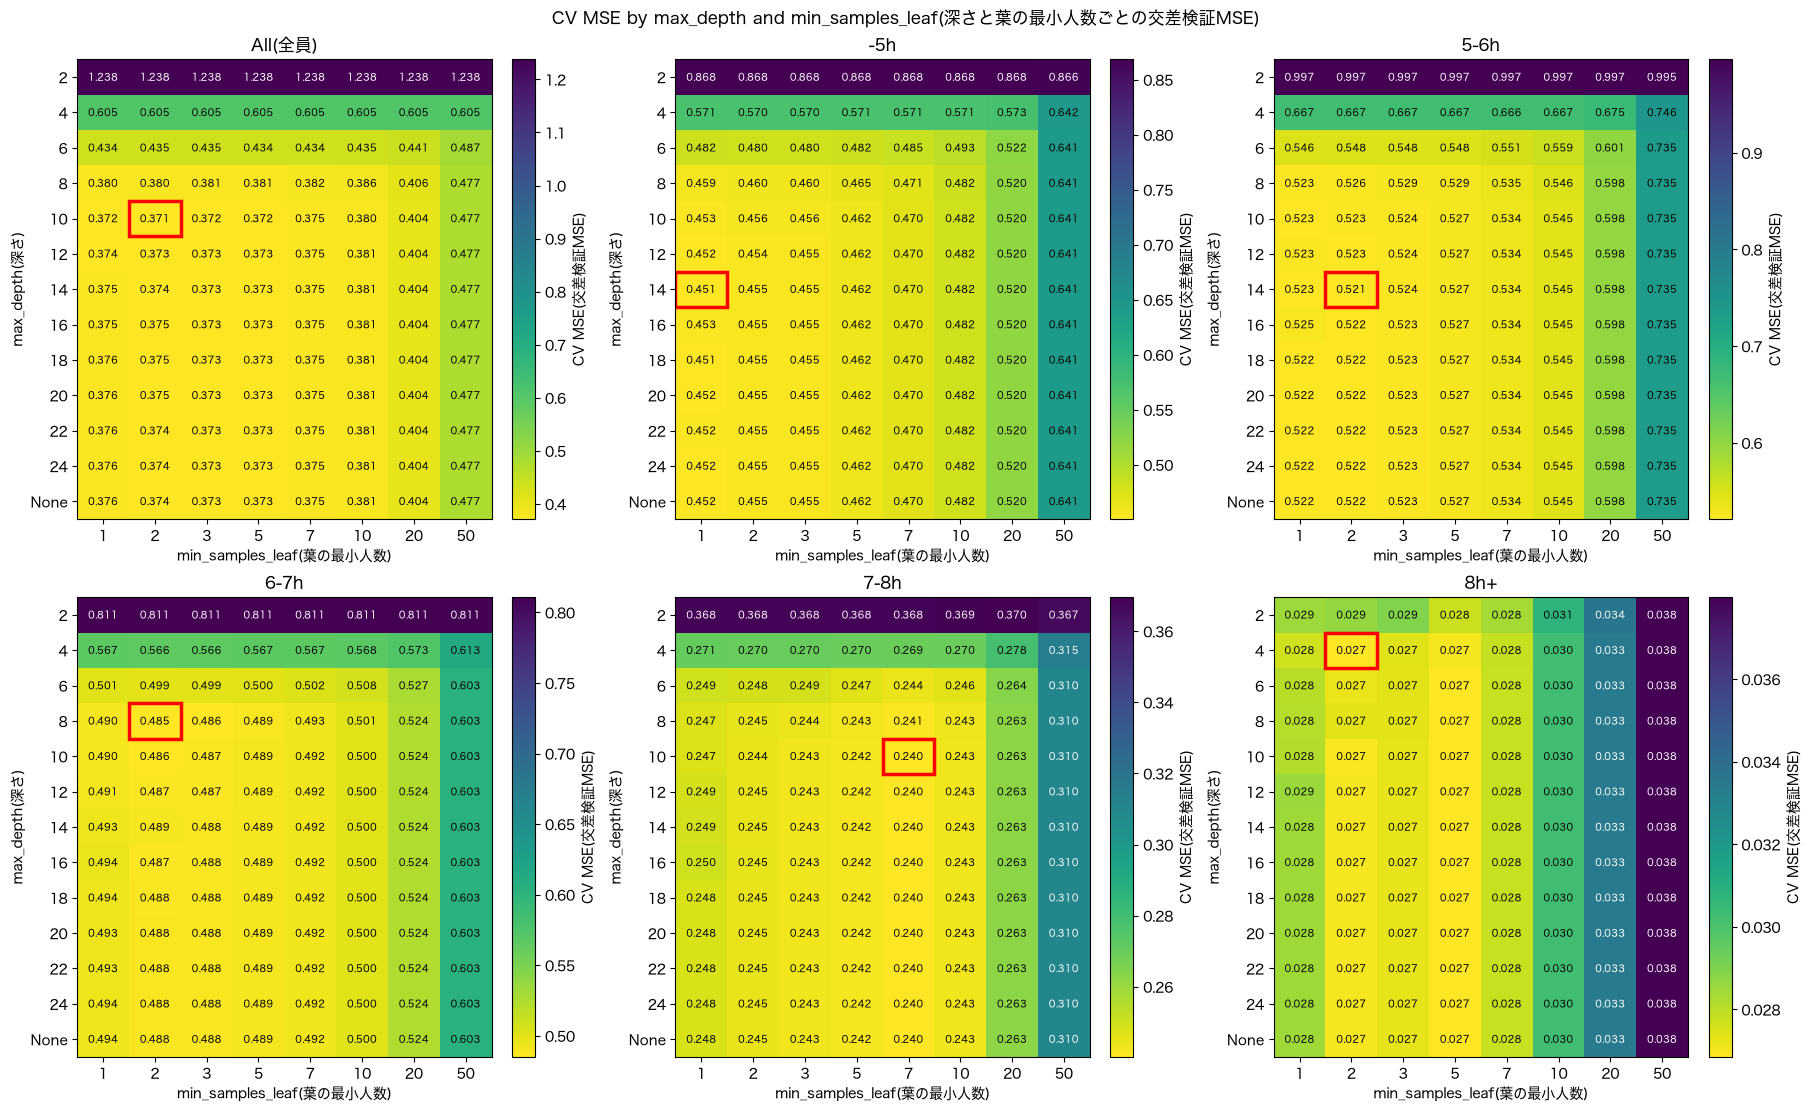

In [19]:
# 深さ × 葉の最小人数ごとの交差検証MSE（行：深さ、列：葉の最小人数）
def cv_pivot(search, score="mean_test_score"):
    res = pd.DataFrame(search.cv_results_)
    table = pd.DataFrame({
        "max_depth": [str(p["max_depth"]) for p in res["params"]],
        "min_samples_leaf": [p["min_samples_leaf"] for p in res["params"]],
        "MSE": -res[score],
    })
    return table.pivot(index="max_depth", columns="min_samples_leaf", values="MSE").loc[[str(d) for d in DEPTHS]]

for name, search in searches.items():
    print(f"CV MSE(交差検証MSE):{name} rows=max_depth(深さ),columns=min_samples_leaf(葉の最小人数)")
    print(cv_pivot(search).round(4).to_string())
    print(f"Best(最良):{search.best_params_},CV MSE(交差検証MSE):{-search.best_score_:.4f}")
    print()

# ヒートマップ。色の範囲はモデルごとに変える（グループで MSE の大きさが大きく違うため）。赤枠が最良
fig, axes = plt.subplots(2, 3, figsize=(18, 11), layout="constrained")
for ax, (name, search) in zip(axes.flatten(), searches.items()):
    piv = cv_pivot(search)
    im = ax.imshow(piv, cmap="viridis_r", aspect="auto")
    mid = (piv.values.min() + piv.values.max()) / 2
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.iloc[i, j]:.3f}", ha="center", va="center", fontsize=7,
                    color="black" if piv.iloc[i, j] < mid else "white")
    bi = piv.index.get_loc(str(search.best_params_["max_depth"]))
    bj = piv.columns.get_loc(search.best_params_["min_samples_leaf"])
    ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, edgecolor="red", linewidth=2.5))
    ax.set_xticks(range(piv.shape[1]), piv.columns)
    ax.set_yticks(range(piv.shape[0]), piv.index)
    ax.set_xlabel("min_samples_leaf(葉の最小人数)")
    ax.set_ylabel("max_depth(深さ)")
    ax.set_title(name)
    fig.colorbar(im, ax=ax, label="CV MSE(交差検証MSE)")
plt.suptitle("CV MSE by max_depth and min_samples_leaf(深さと葉の最小人数ごとの交差検証MSE)")
plt.show()

In [20]:
# 既定値と最良の組み合わせの比較
def cv_row(search, params):
    res = pd.DataFrame(search.cv_results_)
    hit = res["params"].apply(lambda p: p == params)
    return -res.loc[hit, "mean_train_score"].iloc[0], -res.loc[hit, "mean_test_score"].iloc[0]

compare_rows = []
for name, search in searches.items():
    d_train, d_cv = cv_row(search, DEFAULT_PARAMS)
    b_train, b_cv = cv_row(search, search.best_params_)
    compare_rows.append({
        "Model(モデル)": name,
        "Best max_depth(最良の深さ)": str(search.best_params_["max_depth"]),
        "Best min_samples_leaf(最良の葉の最小人数)": search.best_params_["min_samples_leaf"],
        "Default train MSE(既定の学習MSE)": d_train,
        "Default CV MSE(既定の交差検証MSE)": d_cv,
        "Best train MSE(最良の学習MSE)": b_train,
        "Best CV MSE(最良の交差検証MSE)": b_cv,
        "CV MSE change(交差検証MSEの変化)": b_cv - d_cv,
        "Default CV/train(既定の倍率)": d_cv / d_train,
        "Best CV/train(最良の倍率)": b_cv / b_train,
    })
compare_table = pd.DataFrame(compare_rows).set_index("Model(モデル)")
print("Default vs best(既定値と最良の比較):")
print(compare_table.round(4).to_string())

# 調整後のランダムフォレスト（学習データ全体で学習し直したもの）
tuned_base_rf = searches["All(全員)"].best_estimator_
tuned_group_rf = {g: searches[g].best_estimator_ for g in GROUPS}

Default vs best(既定値と最良の比較):
           Best max_depth(最良の深さ)  Best min_samples_leaf(最良の葉の最小人数)  Default train MSE(既定の学習MSE)  Default CV MSE(既定の交差検証MSE)  Best train MSE(最良の学習MSE)  Best CV MSE(最良の交差検証MSE)  CV MSE change(交差検証MSEの変化)  Default CV/train(既定の倍率)  Best CV/train(最良の倍率)
Model(モデル)                                                                                                                                                                                                                                              
All(全員)                       10                                 2                       0.0523                      0.3762                    0.1384                   0.3714                    -0.0048                   7.1888                2.6843
-5h                           14                                 1                       0.0648                      0.4523                    0.0659                   0.4507                    -0.0016                   6.977

## Step 9:Evaluation on test data(テストデータでの評価)

The 1,700 test rows are used for the first time(テストデータ1,700人をここで初めて使う)

- All models(全員のモデル):one model predicts everyone(1つのモデルで全員を予測する)
- Group models(グループ別のモデル):each person is predicted by the model of their own sleep group(各人を、その人の睡眠時間グループのモデルで予測する)
- MSE and R2 are computed for all test rows and for each group(テスト全体と、グループごとに MSE と R2 を計算する)

Test rows(テストの行数):1700
Test data(テストデータの内訳):
                  Test N(テストの人数)  Fatigue mean(疲労の平均)  Fatigue std(疲労の標準偏差)
Test rows(評価した人)                                                           
All(全員)                     1700               3.8239                2.6978
-5h                          343               7.6808                1.7155
5-6h                         364               4.9591                1.6287
6-7h                         419               3.0716                1.3757
7-8h                         377               1.5141                0.8011
8h+                          197               1.0320                0.2110

Test MSE(テストMSE):
                  All LR(全員の線形回帰)  All RF default(全員のRF・既定)  All RF tuned(全員のRF・調整後)  Group LR(グループ別の線形回帰)  Group RF default(グループ別のRF・既定)  Group RF tuned(グループ別のRF・調整後)
Test rows(評価した人)                                                                                                                                                

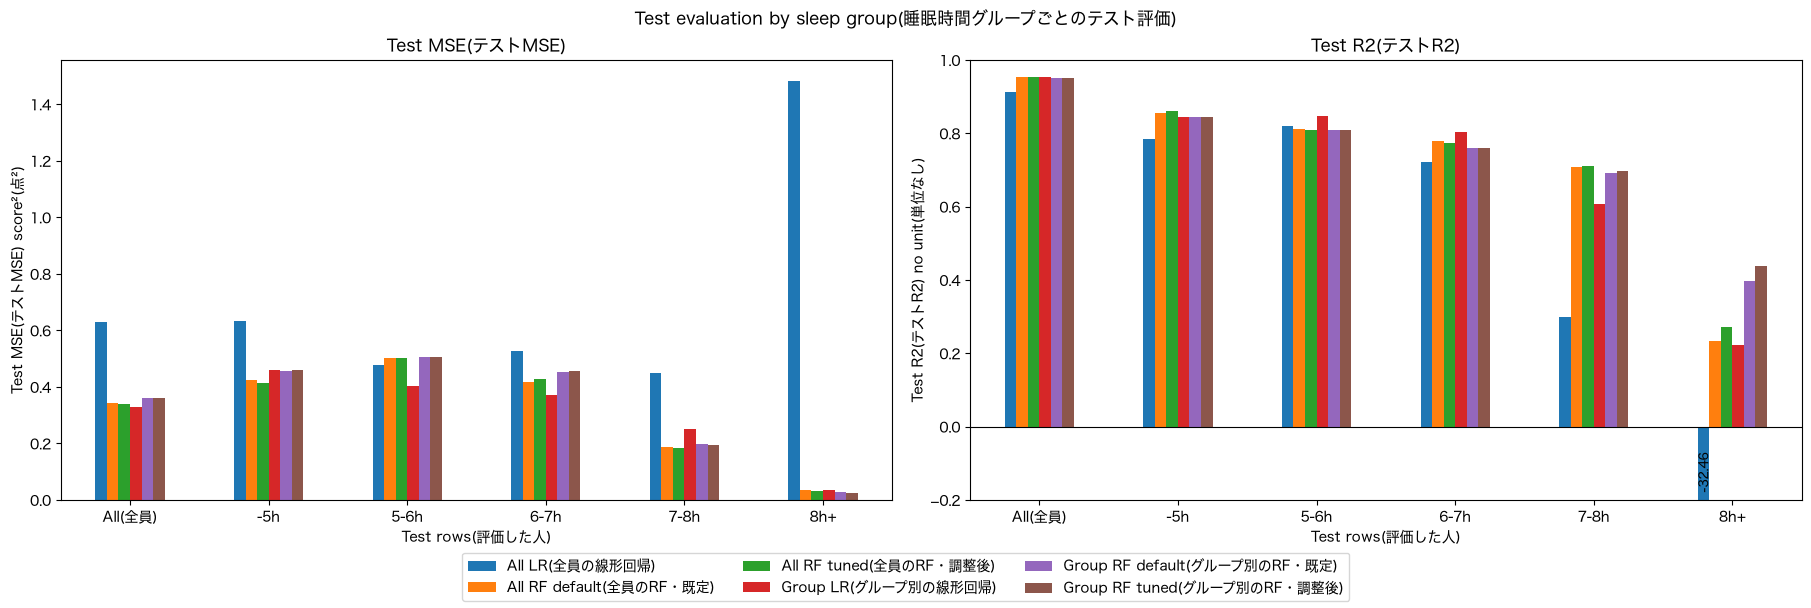

In [21]:
# モデル名と、グループ g の人を予測するときに使うモデル
MODELS = {
    "All LR(全員の線形回帰)": lambda g: base_lr,
    "All RF default(全員のRF・既定)": lambda g: base_rf,
    "All RF tuned(全員のRF・調整後)": lambda g: tuned_base_rf,
    "Group LR(グループ別の線形回帰)": lambda g: group_models[g][1],
    "Group RF default(グループ別のRF・既定)": lambda g: group_models[g][0],
    "Group RF tuned(グループ別のRF・調整後)": lambda g: tuned_group_rf[g],
}

# テストデータの予測値（行：人、列：モデル）
test_pred = pd.DataFrame(index=X_test.index, columns=list(MODELS), dtype=float)
for g in GROUPS:
    in_g = group_test == g
    for name, get_model in MODELS.items():
        test_pred.loc[in_g, name] = get_model(g).predict(X_test[in_g])

# テスト全体とグループごとの MSE と R2
ALL = "All(全員)"
ROWS = [ALL] + GROUPS
info_rows, mse_rows, r2_rows = [], [], []
for row in ROWS:
    in_r = pd.Series(True, index=y_test.index) if row == ALL else group_test == row
    y_r = y_test[in_r]
    info_rows.append({"Test N(テストの人数)": in_r.sum(), "Fatigue mean(疲労の平均)": y_r.mean(), "Fatigue std(疲労の標準偏差)": y_r.std()})
    mse_rows.append({name: mean_squared_error(y_r, test_pred.loc[in_r, name]) for name in MODELS})
    r2_rows.append({name: r2_score(y_r, test_pred.loc[in_r, name]) for name in MODELS})
info_table = pd.DataFrame(info_rows, index=ROWS)
mse_table = pd.DataFrame(mse_rows, index=ROWS)
r2_table = pd.DataFrame(r2_rows, index=ROWS)
for table in [info_table, mse_table, r2_table]:
    table.index.name = "Test rows(評価した人)"

# グループ別のモデルから全員のモデルを引いた MSE の差（マイナスならグループ別のほうが良い）
diff_table = pd.DataFrame({
    "LR:Group-All(線形回帰:グループ別-全員)": mse_table["Group LR(グループ別の線形回帰)"] - mse_table["All LR(全員の線形回帰)"],
    "RF tuned:Group-All(調整後RF:グループ別-全員)": mse_table["Group RF tuned(グループ別のRF・調整後)"] - mse_table["All RF tuned(全員のRF・調整後)"],
})

print(f"Test rows(テストの行数):{len(X_test)}")
print("Test data(テストデータの内訳):")
print(info_table.round(4).to_string())
print()
print("Test MSE(テストMSE):")
print(mse_table.round(4).to_string())
print()
print("Test R2(テストR2):")
print(r2_table.round(4).to_string())
print()
print("MSE difference(MSEの差):")
print(diff_table.round(4).to_string())
print()
print("Lowest MSE model(MSEが最も小さいモデル):")
print(mse_table.idxmin(axis=1).to_string())

# 図：テストMSE とテストR2 をモデルごとに並べる
fig, axes = plt.subplots(1, 2, figsize=(18, 6), layout="constrained")
mse_table.plot.bar(ax=axes[0], legend=False, rot=0)
axes[0].set_ylabel("Test MSE(テストMSE) score²(点²)")
axes[0].set_title("Test MSE(テストMSE)")
r2_table.plot.bar(ax=axes[1], legend=False, rot=0)
axes[1].set_ylabel("Test R2(テストR2) no unit(単位なし)")
axes[1].set_title("Test R2(テストR2)")
# R2 が大きくマイナスになる棒は軸の下端で切り、値を書き込む（棒は列ごとに、行の順で描かれる）
R2_BOTTOM = -0.2
axes[1].set_ylim(R2_BOTTOM, 1)
axes[1].axhline(0, color="black", linewidth=0.8)
for bar, value in zip(axes[1].patches, r2_table.T.values.flatten()):
    if value < R2_BOTTOM:
        axes[1].text(bar.get_x() + bar.get_width() / 2, R2_BOTTOM + 0.02, f"{value:.2f}",
                     ha="center", va="bottom", rotation=90, fontsize=9)
for ax in axes:
    ax.set_xlabel("Test rows(評価した人)")
fig.legend(axes[0].get_legend_handles_labels()[0], list(MODELS), loc="outside lower center", ncol=3)
plt.suptitle("Test evaluation by sleep group(睡眠時間グループごとのテスト評価)")
plt.show()

## Step 10:Interpretation of linear regression(線形回帰の解釈)

Coefficients of the group models are compared in original units(グループ別の線形回帰の係数を、元の単位のまま比べる)

- 10-1:Equations and coefficients(式と係数)
- 10-2:Confidence intervals and correlated features with statsmodels OLS(statsmodels の OLS で、信頼区間と相関の強い特徴量)
- 10-3:Model without sleep_latency and snoozes(sleep_latency と snoozes を除いたモデル)

In [22]:
import os
import numpy as np

# 図の保存先（レポート用）
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# 係数の単位：特徴量が1単位増えたときに、疲労が何点変わるか
COEF_UNITS = {
    "bedtime_phone_minutes": "score/min(点/分)",
    "screen_brightness_pct": "score/%(点/%)",
    "blue_light_filter_active": "score,on-off(点、あり-なし)",
    "caffeine_post_5pm_mg": "score/mg(点/mg)",
    "physical_activity_min": "score/min(点/分)",
    "sleep_latency_min": "score/min(点/分)",
    "total_sleep_hours": "score/h(点/時間)",
    "deep_sleep_pct": "score/%(点/%)",
    "rem_sleep_pct": "score/%(点/%)",
    "morning_alarm_snoozes": "score/time(点/回)",
}

# 線形回帰：全員のモデル（Step 6）とグループ別のモデル（Step 7）
ALL = "All(全員)"
LR_MODELS = {ALL: base_lr} | {g: group_models[g][1] for g in GROUPS}

# 係数の表（行：切片と特徴量、列：モデル）
coef_by_group = pd.DataFrame(
    {name: [lr.intercept_] + list(lr.coef_) for name, lr in LR_MODELS.items()},
    index=["intercept(切片)"] + FEATURES,
)
coef_by_group.insert(0, "Coefficient unit(係数の単位)", ["score(点)"] + [COEF_UNITS[col] for col in FEATURES])
coef_by_group.index.name = "Term(項)"

print("Equations(式):y=next_day_fatigue_score(翌日の疲労)")
for name, lr in LR_MODELS.items():
    terms = "".join(f"{'+' if c >= 0 else '-'}{abs(c):.4f}×{col}" for col, c in zip(FEATURES, lr.coef_))
    print(f"{name}:y={lr.intercept_:.4f}{terms}")
print()
print("Coefficients(係数):")
print(coef_by_group.round(4).to_string())

Equations(式):y=next_day_fatigue_score(翌日の疲労)
All(全員):y=8.1686+0.0063×bedtime_phone_minutes+0.0049×screen_brightness_pct-0.1475×blue_light_filter_active+0.0038×caffeine_post_5pm_mg+0.0005×physical_activity_min+0.0293×sleep_latency_min-0.9391×total_sleep_hours-0.0652×deep_sleep_pct-0.0035×rem_sleep_pct+0.3909×morning_alarm_snoozes
-5h:y=8.8996+0.0060×bedtime_phone_minutes+0.0066×screen_brightness_pct-0.1786×blue_light_filter_active+0.0045×caffeine_post_5pm_mg-0.0003×physical_activity_min+0.0237×sleep_latency_min-0.9683×total_sleep_hours-0.0644×deep_sleep_pct-0.0114×rem_sleep_pct+0.4171×morning_alarm_snoozes
5-6h:y=9.7654+0.0041×bedtime_phone_minutes+0.0055×screen_brightness_pct-0.1451×blue_light_filter_active+0.0051×caffeine_post_5pm_mg+0.0022×physical_activity_min+0.0397×sleep_latency_min-1.2868×total_sleep_hours-0.0876×deep_sleep_pct+0.0011×rem_sleep_pct+0.4563×morning_alarm_snoozes
6-7h:y=9.3490+0.0039×bedtime_phone_minutes+0.0058×screen_brightness_pct-0.1329×blue_light_filter_active+

Max difference from sklearn coefficients(sklearnの係数との差の最大):7.67e-14
All(全員):N(人数)=6800,df model(モデルの自由度)=10,df resid(残差の自由度)=6789,R2=0.9115
-5h:N(人数)=1370,df model(モデルの自由度)=10,df resid(残差の自由度)=1359,R2=0.8396
5-6h:N(人数)=1456,df model(モデルの自由度)=10,df resid(残差の自由度)=1445,R2=0.8291
6-7h:N(人数)=1678,df model(モデルの自由度)=10,df resid(残差の自由度)=1667,R2=0.7753
7-8h:N(人数)=1510,df model(モデルの自由度)=10,df resid(残差の自由度)=1499,R2=0.6429
8h+:N(人数)=786,df model(モデルの自由度)=10,df resid(残差の自由度)=775,R2=0.2176

Coefficient[95% CI](係数［95%信頼区間］):
                                           All(全員)                       -5h                      5-6h                      6-7h                      7-8h                      8h+
Feature(特徴量)                                                                                                                                                                       
bedtime_phone_minutes        0.0063[0.0051,0.0074]       0.006[0.0041,0.008]     0.0041[0.0022,0.0059]      0.0039[0.002,0.0

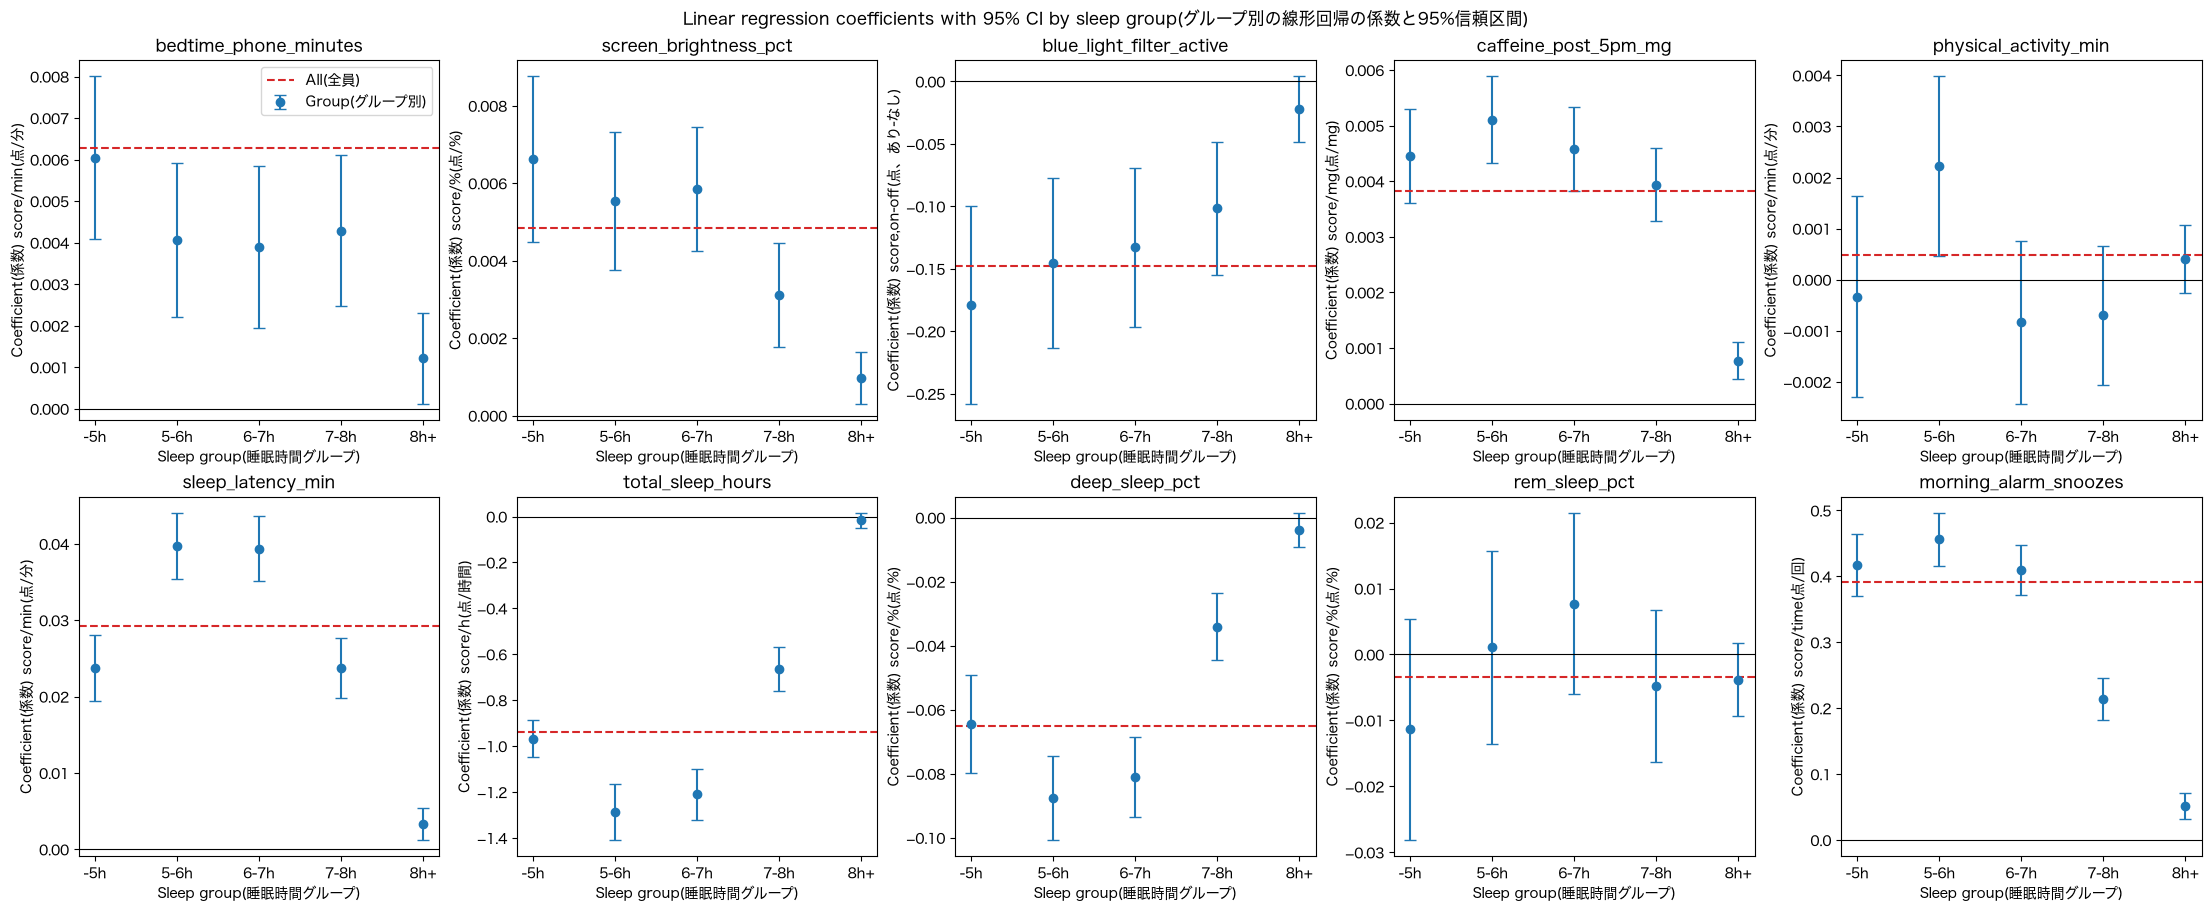

In [23]:
import statsmodels.api as sm

# 各モデルを statsmodels の OLS で学習し直し、係数の95%信頼区間と p値を出す（係数は sklearn と同じになる）
def rows_of(name, groups_part):
    return pd.Series(True, index=groups_part.index) if name == ALL else groups_part == name

ols_results = {}
for name in LR_MODELS:
    in_r = rows_of(name, group_train)
    ols_results[name] = sm.OLS(y_train[in_r], sm.add_constant(X_train[in_r])).fit()

max_diff = max((ols_results[name].params[FEATURES] - lr.coef_).abs().max() for name, lr in LR_MODELS.items())
print(f"Max difference from sklearn coefficients(sklearnの係数との差の最大):{max_diff:.2e}")
for name, res in ols_results.items():
    print(f"{name}:N(人数)={int(res.nobs)},df model(モデルの自由度)={int(res.df_model)},df resid(残差の自由度)={int(res.df_resid)},R2={res.rsquared:.4f}")
print()

# 係数［95%下限,95%上限］の表と p値の表（行：特徴量、列：モデル）
ci_low = pd.DataFrame({name: res.conf_int().loc[FEATURES, 0] for name, res in ols_results.items()})
ci_high = pd.DataFrame({name: res.conf_int().loc[FEATURES, 1] for name, res in ols_results.items()})
coef_ols = pd.DataFrame({name: res.params[FEATURES] for name, res in ols_results.items()})
p_table = pd.DataFrame({name: res.pvalues[FEATURES] for name, res in ols_results.items()})
ci_text = coef_ols.round(4).astype(str) + "[" + ci_low.round(4).astype(str) + "," + ci_high.round(4).astype(str) + "]"
for table in [ci_text, p_table]:
    table.index.name = "Feature(特徴量)"
print("Coefficient[95% CI](係数［95%信頼区間］):")
print(ci_text.to_string())
print()
print("p-value(p値):")
print(p_table.map(lambda p: f"{p:.2e}").to_string())
print()
print("Significant at 5%(5%で有意):")
print((p_table < 0.05).to_string())
print()

# 相関の強い特徴量の組（学習データ、|r|>0.5）
CORR_PAIR_THRESHOLD = 0.5
corr_pair_rows = []
for name in LR_MODELS:
    corr = X_train[rows_of(name, group_train)].corr()
    for i, a in enumerate(FEATURES):
        for b in FEATURES[i + 1:]:
            if abs(corr.loc[a, b]) > CORR_PAIR_THRESHOLD:
                corr_pair_rows.append({"Model(モデル)": name, "Feature A(特徴量A)": a, "Feature B(特徴量B)": b, "r(相関係数)": corr.loc[a, b]})
corr_pair_table = pd.DataFrame(corr_pair_rows)
print(f"Feature pairs with |r|>{CORR_PAIR_THRESHOLD}(相関の強い特徴量の組):")
print(corr_pair_table.round(4).to_string(index=False))

# 図：特徴量ごとに、グループ別の係数と95%信頼区間。破線は全員のモデルの係数
fig, axes = plt.subplots(2, 5, figsize=(22, 9), layout="constrained")
x = range(len(GROUPS))
for ax, col in zip(axes.flatten(), FEATURES):
    est = coef_ols.loc[col, GROUPS]
    err = [est - ci_low.loc[col, GROUPS], ci_high.loc[col, GROUPS] - est]
    ax.errorbar(x, est, yerr=err, fmt="o", capsize=4, color="tab:blue", label="Group(グループ別)")
    ax.axhline(coef_ols.loc[col, ALL], color="tab:red", linestyle="--", label="All(全員)")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x, GROUPS)
    ax.set_xlabel("Sleep group(睡眠時間グループ)")
    ax.set_ylabel(f"Coefficient(係数) {COEF_UNITS[col]}")
    ax.set_title(col)
axes[0, 0].legend()
plt.suptitle("Linear regression coefficients with 95% CI by sleep group(グループ別の線形回帰の係数と95%信頼区間)")
fig.savefig(f"{FIG_DIR}/coef_by_group.png", dpi=150)
plt.show()

In [24]:
# sleep_latency と snoozes は「睡眠の悪さ・疲れの結果」でもあり得る（疲れているからスヌーズが増える＝逆因果の可能性）
# この2つを除いたモデルを作り、ほかの要因の係数と予測の良さがどう変わるかを見る
DROP = ["sleep_latency_min", "morning_alarm_snoozes"]
REDUCED = [col for col in FEATURES if col not in DROP]

reduced_coef, reduced_eval = {}, []
for name, full_lr in LR_MODELS.items():
    in_tr = rows_of(name, group_train)
    in_te = rows_of(name, group_test)
    lr = LinearRegression().fit(X_train.loc[in_tr, REDUCED], y_train[in_tr])
    reduced_coef[name] = pd.Series(lr.coef_, index=REDUCED)
    full_pred = full_lr.predict(X_test[in_te])
    reduced_pred = lr.predict(X_test.loc[in_te, REDUCED])
    reduced_eval.append({
        "Model(モデル)": name,
        "Full test MSE(10個のテストMSE)": mean_squared_error(y_test[in_te], full_pred),
        "Reduced test MSE(8個のテストMSE)": mean_squared_error(y_test[in_te], reduced_pred),
        "Full test R2(10個のテストR2)": r2_score(y_test[in_te], full_pred),
        "Reduced test R2(8個のテストR2)": r2_score(y_test[in_te], reduced_pred),
    })
reduced_coef = pd.DataFrame(reduced_coef)
reduced_eval = pd.DataFrame(reduced_eval).set_index("Model(モデル)")
coef_change = reduced_coef - coef_by_group.loc[REDUCED, list(LR_MODELS)]
for table in [reduced_coef, coef_change]:
    table.index.name = "Feature(特徴量)"

print(f"Dropped features(除いた特徴量):{DROP}")
print(f"Remaining features(残した特徴量の数):{len(REDUCED)}")
print()
print("Test evaluation(テスト評価):")
print(reduced_eval.round(4).to_string())
print()
print("Coefficients without the 2 features(2つを除いたモデルの係数):")
print(reduced_coef.round(4).to_string())
print()
print("Change from the full model(10個のモデルからの変化＝8個-10個):")
print(coef_change.round(4).to_string())

Dropped features(除いた特徴量):['sleep_latency_min', 'morning_alarm_snoozes']
Remaining features(残した特徴量の数):8

Test evaluation(テスト評価):
            Full test MSE(10個のテストMSE)  Reduced test MSE(8個のテストMSE)  Full test R2(10個のテストR2)  Reduced test R2(8個のテストR2)
Model(モデル)                                                                                                            
All(全員)                        0.6308                       0.8468                   0.9133                     0.8836
-5h                            0.4577                       0.7148                   0.8440                     0.7564
5-6h                           0.4044                       0.7636                   0.8471                     0.7114
6-7h                           0.3702                       0.6307                   0.8039                     0.6659
7-8h                           0.2521                       0.3301                   0.6060                     0.4842
8h+                            0.0345  

## Step 11:Interpretation of random forest with SHAP(SHAPによるランダムフォレストの解釈)

TreeSHAP on the tuned random forests from Step 8, computed on the test rows of each group(Step 8 の調整後RFに TreeSHAP を使い、各グループのテストデータで計算する)

- Mean |SHAP|(平均|SHAP|):how many points the feature moves the prediction on average(その特徴量が予測を平均で何点動かすか)
- Share(割合):mean |SHAP| divided by the total of the group(グループ内の合計に対する割合。グループ間で大きさが違うので割合でも比べる)
- Direction(向き):correlation between the feature value and its SHAP value(特徴量の値と SHAP 値の相関。プラスなら値が大きいほど疲労の予測が上がる)

/Users/ch1nam1/Documents/ICU/isc353_TopicsInInformationScience/final_report/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All(全員):Test N(テストの人数)=1700,Max additivity error(基準値+SHAPと予測値の差の最大)=1.26e-13
-5h:Test N(テストの人数)=343,Max additivity error(基準値+SHAPと予測値の差の最大)=3.82e-14
5-6h:Test N(テストの人数)=364,Max additivity error(基準値+SHAPと予測値の差の最大)=4.09e-14
6-7h:Test N(テストの人数)=419,Max additivity error(基準値+SHAPと予測値の差の最大)=1.55e-14
7-8h:Test N(テストの人数)=377,Max additivity error(基準値+SHAPと予測値の差の最大)=7.55e-15
8h+:Test N(テストの人数)=197,Max additivity error(基準値+SHAPと予測値の差の最大)=8.88e-16

Mean |SHAP|(平均|SHAP|) score(点):
                          All(全員)     -5h    5-6h    6-7h    7-8h     8h+
Feature(特徴量)                                                             
bedtime_phone_minutes      0.0281  0.0398  0.0265  0.0225  0.0209  0.0034
screen_brightness_pct      0.0331  0.0504  0.0552  0.0510  0.0197  0.0034
blue_light_filter_active   0.0078  0.0161  0.0170  0.0118  0.0051  0.0006
caffeine_post_5pm_mg       0.1039  0.1076  0.1482  0.1150  0.1044  0.0135
physical_activity_min      0.0075  0.0182  0.0145  0.0115  0.0053  0.0017
sleep_lat

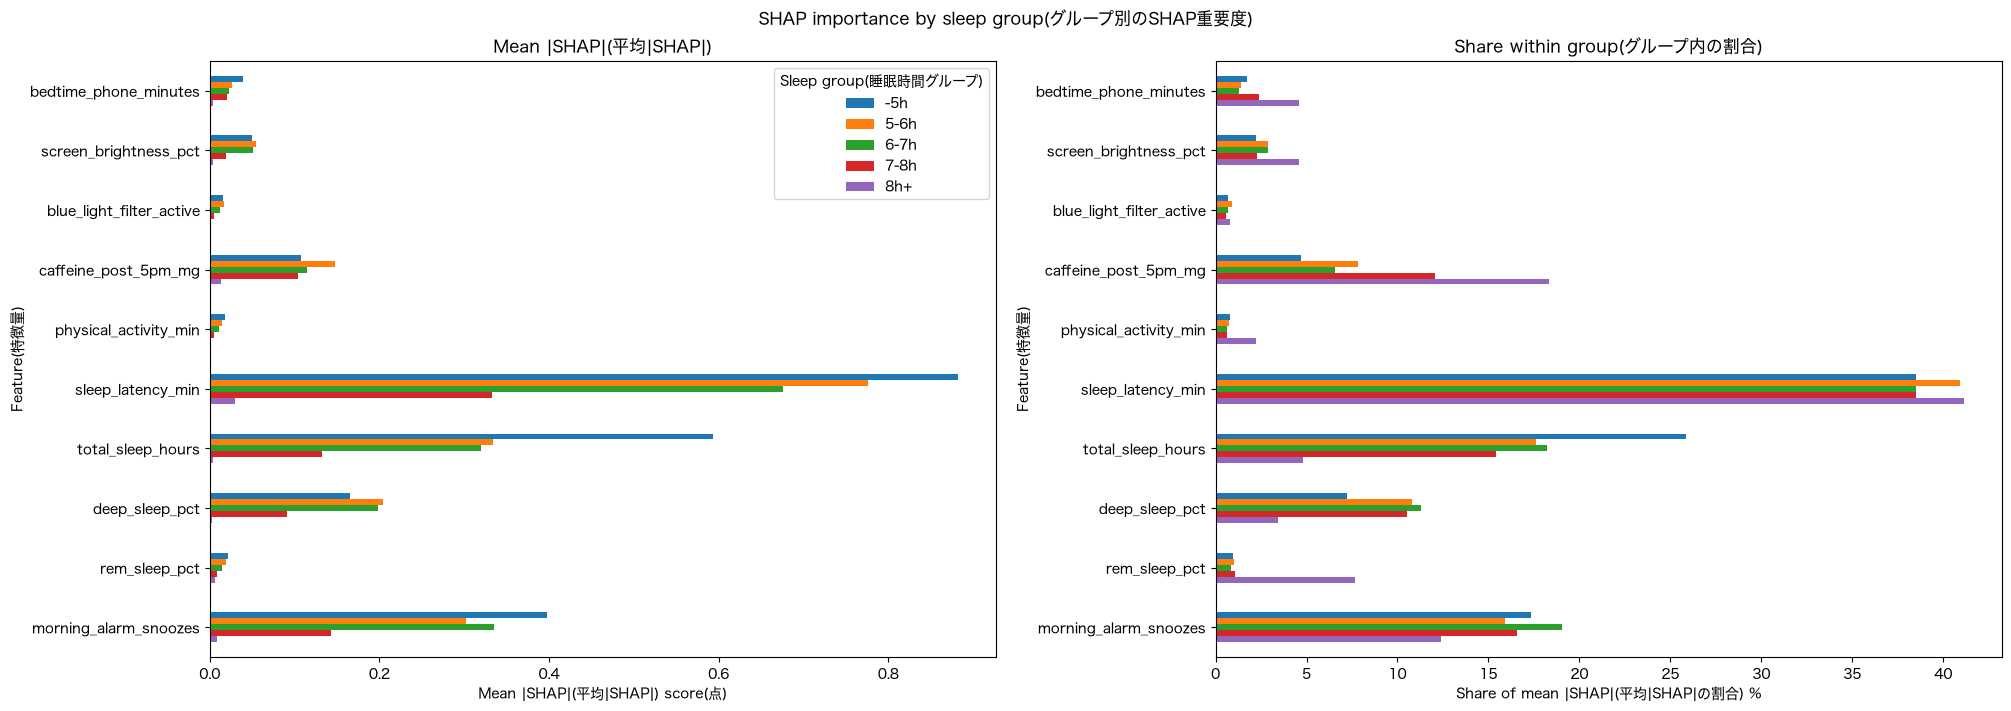

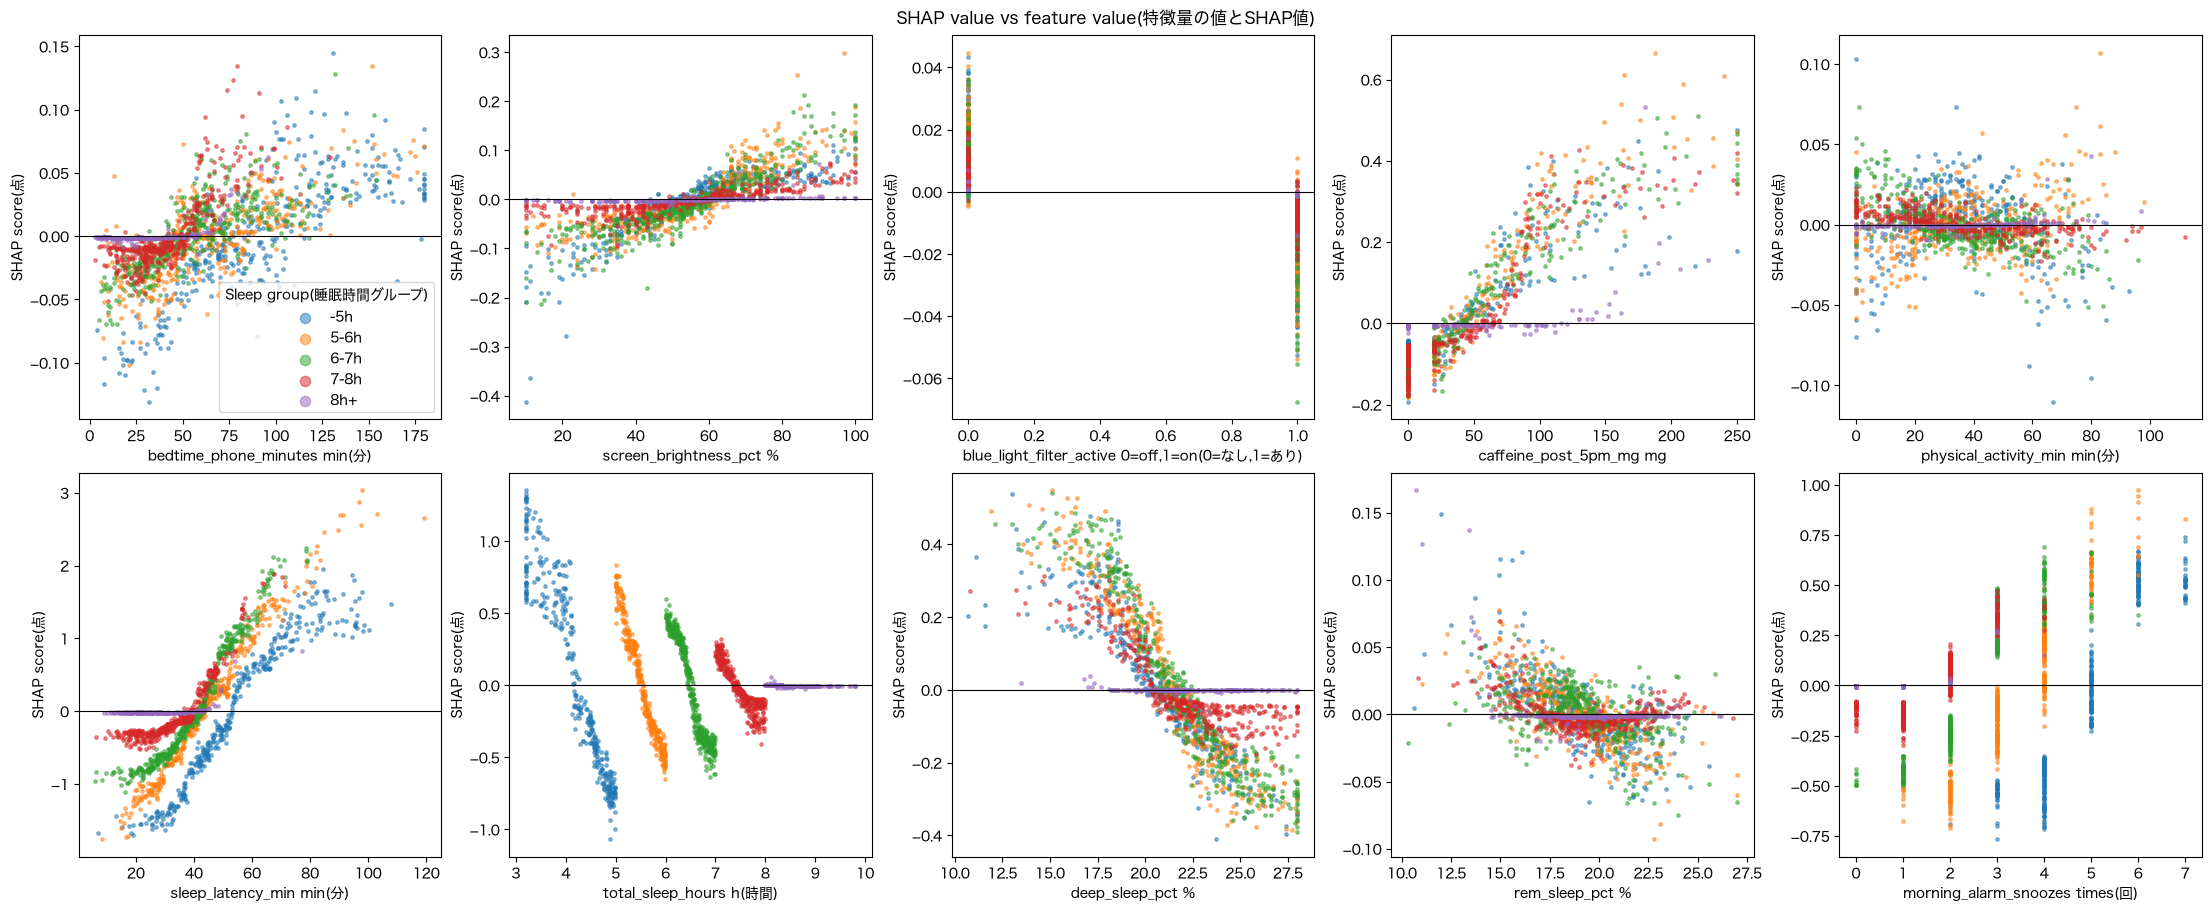

In [25]:
import shap

SHAP_MODELS = {ALL: tuned_base_rf} | tuned_group_rf
shap_values, additivity_error = {}, {}
for name, rf in SHAP_MODELS.items():
    in_te = rows_of(name, group_test)
    explainer = shap.TreeExplainer(rf)
    values = explainer.shap_values(X_test[in_te])
    shap_values[name] = pd.DataFrame(values, index=X_test.index[in_te], columns=FEATURES)
    # 確認：基準値＋SHAP の合計＝予測値
    additivity_error[name] = np.abs(explainer.expected_value + values.sum(axis=1) - rf.predict(X_test[in_te])).max()

mean_abs_shap = pd.DataFrame({name: sv.abs().mean() for name, sv in shap_values.items()})
shap_share = mean_abs_shap.div(mean_abs_shap.sum()) * 100
shap_rank = mean_abs_shap.rank(ascending=False).astype(int)
shap_direction = pd.DataFrame({
    name: pd.Series({col: X_test.loc[sv.index, col].corr(sv[col]) for col in FEATURES})
    for name, sv in shap_values.items()
})
for table in [mean_abs_shap, shap_share, shap_rank, shap_direction]:
    table.index.name = "Feature(特徴量)"

for name, sv in shap_values.items():
    print(f"{name}:Test N(テストの人数)={len(sv)},Max additivity error(基準値+SHAPと予測値の差の最大)={additivity_error[name]:.2e}")
print()
print("Mean |SHAP|(平均|SHAP|) score(点):")
print(mean_abs_shap.round(4).to_string())
print()
print("Share of mean |SHAP|(平均|SHAP|の割合) %:")
print(shap_share.round(2).to_string())
print()
print("Rank(順位):")
print(shap_rank.to_string())
print()
print("Direction(向き)=corr(feature value,SHAP)(特徴量の値とSHAPの相関):")
print(shap_direction.round(3).to_string())

# 図1：平均|SHAP| と割合（グループ別）
fig, axes = plt.subplots(1, 2, figsize=(20, 7), layout="constrained")
mean_abs_shap[GROUPS].plot.barh(ax=axes[0])
axes[0].set_xlabel("Mean |SHAP|(平均|SHAP|) score(点)")
axes[0].set_title("Mean |SHAP|(平均|SHAP|)")
shap_share[GROUPS].plot.barh(ax=axes[1], legend=False)
axes[1].set_xlabel("Share of mean |SHAP|(平均|SHAP|の割合) %")
axes[1].set_title("Share within group(グループ内の割合)")
for ax in axes:
    ax.set_ylabel("Feature(特徴量)")
    ax.invert_yaxis()
axes[0].legend(title="Sleep group(睡眠時間グループ)")
plt.suptitle("SHAP importance by sleep group(グループ別のSHAP重要度)")
fig.savefig(f"{FIG_DIR}/shap_by_group.png", dpi=150)
plt.show()

# 図2：特徴量の値と SHAP 値（色はグループ）
fig, axes = plt.subplots(2, 5, figsize=(22, 9), layout="constrained")
for ax, col in zip(axes.flatten(), FEATURES):
    for g in GROUPS:
        ax.scatter(X_test.loc[shap_values[g].index, col], shap_values[g][col], s=6, alpha=0.5, label=g)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel(f"{col} {UNITS[col]}")
    ax.set_ylabel("SHAP score(点)")
axes[0, 0].legend(title="Sleep group(睡眠時間グループ)", markerscale=3)
plt.suptitle("SHAP value vs feature value(特徴量の値とSHAP値)")
fig.savefig(f"{FIG_DIR}/shap_dependence.png", dpi=150)
plt.show()

## Step 12:Robustness check with overlapping windows(重なる区切りでの頑健性の確認)

Suggested by Oliver(Oliverの提案):windows of 1 hour width moved by 30 minutes, so the position of the cut matters less(幅1時間の窓を30分ずつずらし、区切りの位置に結果が左右されにくくする)

- One person can be in two windows, so windows are not independent(1人が2つの窓に入るので、窓同士は独立ではない)→used only to check the trend, not for tests(傾向の確認だけに使い、検定には使わない)
- Each window is trained on its train rows and evaluated on its test rows(各窓の学習データで学習し、窓のテストデータで評価する)
- Random forest settings are fixed from the flat area of the Step 8 heatmaps(RF の設定は、Step 8 のヒートマップで平らだった範囲から1つに固定する)

Window width(窓の幅):1.0h
Window step(ずらし幅):0.5h
Number of windows(窓の数):13
Fitted windows(学習した窓の数、学習の人数100人以上かつ疲労の標準偏差>0):11
RF settings(RFの設定):{'n_estimators': 100, 'max_depth': 10, 'min_samples_leaf': 5}

                  Low(下限) h(時間)  High(上限) h(時間)  Train N(学習の人数)  Test N(テストの人数)  Mean sleep(平均睡眠時間) h(時間)  Fatigue mean(疲労の平均)  Fatigue std(疲労の標準偏差)  At 10.0 ratio(疲労10.0の割合)  At 1.0 ratio(疲労1.0の割合)  Fitted(学習した)  LR test MSE(線形回帰のテストMSE)  RF test MSE(RFのテストMSE)
Center(中心) h(時間)                                                                                                                                                                                                                                                      
3.5                         3.0             4.0             518             129                    3.4842               8.9900                1.1956                    0.4073                  0.0000          True                    0.3239                  0.3585
4.0    

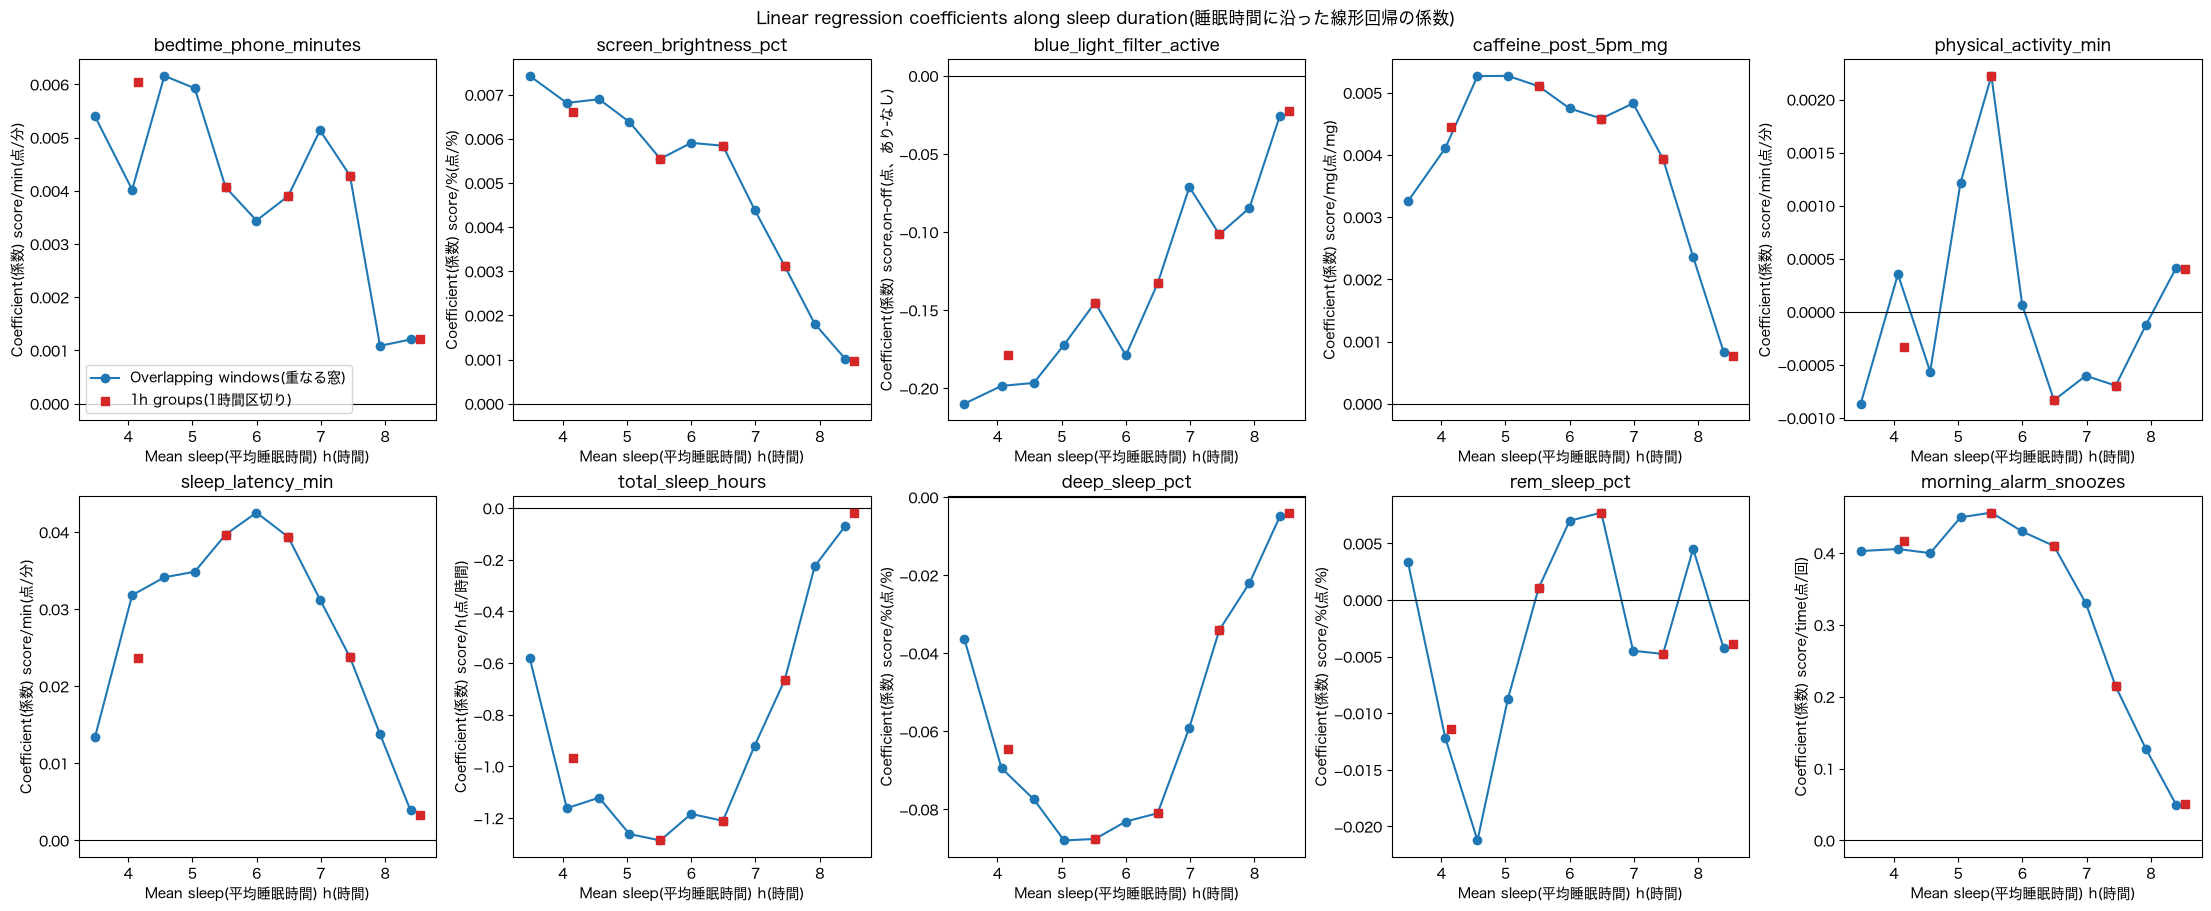

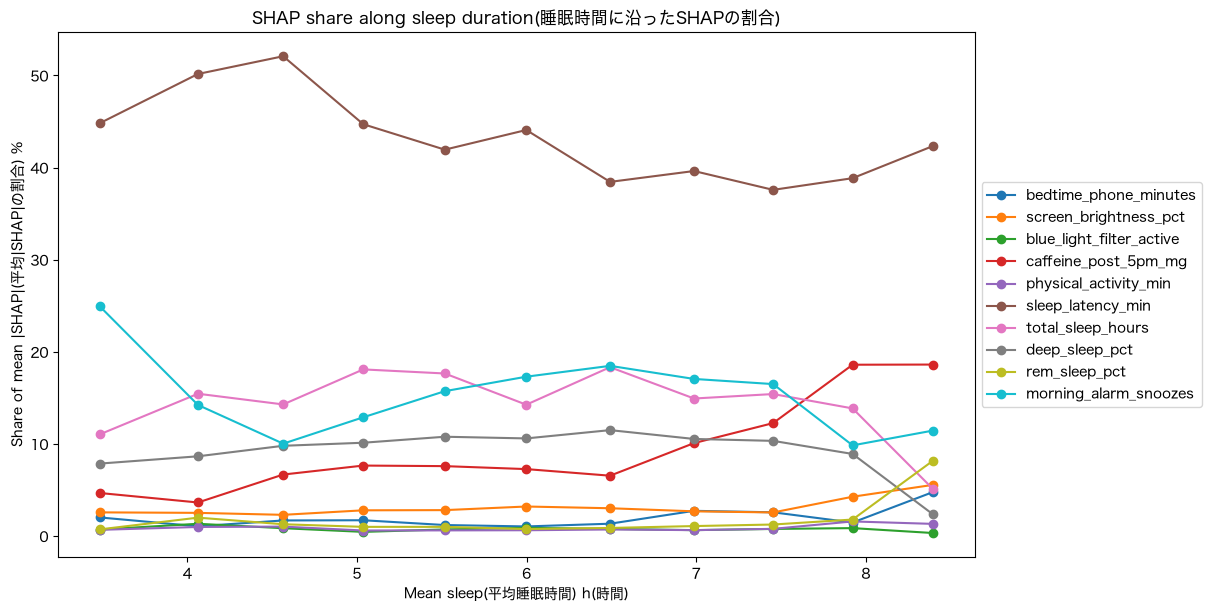

In [26]:
WINDOW_WIDTH = 1.0
WINDOW_STEP = 0.5
MIN_TRAIN_N = 100
WINDOW_RF_PARAMS = {"n_estimators": 100, "max_depth": 10, "min_samples_leaf": 5}

# 窓の中心：睡眠時間の範囲（3.2〜9.8時間）を覆うように 3.5,4.0,...,9.5
centers = np.arange(3.5, 9.5 + WINDOW_STEP / 2, WINDOW_STEP)
sleep_train = X_train[SLEEP]
sleep_test = X_test[SLEEP]

window_rows, window_coef, window_shap_share = [], {}, {}
for c in centers:
    low, high = c - WINDOW_WIDTH / 2, c + WINDOW_WIDTH / 2
    in_tr = (sleep_train >= low) & (sleep_train < high)
    in_te = (sleep_test >= low) & (sleep_test < high)
    row = {
        "Center(中心) h(時間)": c,
        "Low(下限) h(時間)": low,
        "High(上限) h(時間)": high,
        "Train N(学習の人数)": int(in_tr.sum()),
        "Test N(テストの人数)": int(in_te.sum()),
        "Mean sleep(平均睡眠時間) h(時間)": sleep_train[in_tr].mean(),
        "Fatigue mean(疲労の平均)": y_train[in_tr].mean(),
        "Fatigue std(疲労の標準偏差)": y_train[in_tr].std(),
        "At 10.0 ratio(疲労10.0の割合)": y_train[in_tr].eq(10.0).mean(),
        "At 1.0 ratio(疲労1.0の割合)": y_train[in_tr].eq(1.0).mean(),
        # 疲労が全員同じ（標準偏差0）の窓は、説明するばらつきがないので学習しない
        "Fitted(学習した)": (in_tr.sum() >= MIN_TRAIN_N) and (y_train[in_tr].std() > 0),
    }
    if row["Fitted(学習した)"]:
        lr = LinearRegression().fit(X_train[in_tr], y_train[in_tr])
        rf = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **WINDOW_RF_PARAMS).fit(X_train[in_tr], y_train[in_tr])
        row["LR test MSE(線形回帰のテストMSE)"] = mean_squared_error(y_test[in_te], lr.predict(X_test[in_te]))
        row["RF test MSE(RFのテストMSE)"] = mean_squared_error(y_test[in_te], rf.predict(X_test[in_te]))
        window_coef[c] = pd.Series(lr.coef_, index=FEATURES)
        values = pd.DataFrame(shap.TreeExplainer(rf).shap_values(X_test[in_te]), columns=FEATURES)
        window_shap_share[c] = values.abs().mean() / values.abs().mean().sum() * 100
    window_rows.append(row)

window_table = pd.DataFrame(window_rows).set_index("Center(中心) h(時間)")
window_coef = pd.DataFrame(window_coef).T
window_shap_share = pd.DataFrame(window_shap_share).T
for table in [window_coef, window_shap_share]:
    table.index.name = "Center(中心) h(時間)"

print(f"Window width(窓の幅):{WINDOW_WIDTH}h")
print(f"Window step(ずらし幅):{WINDOW_STEP}h")
print(f"Number of windows(窓の数):{len(centers)}")
print(f"Fitted windows(学習した窓の数、学習の人数{MIN_TRAIN_N}人以上かつ疲労の標準偏差>0):{int(window_table['Fitted(学習した)'].sum())}")
print(f"RF settings(RFの設定):{WINDOW_RF_PARAMS}")
print()
print(window_table.round(4).to_string())
print()
print("LR coefficients by window(窓ごとの線形回帰の係数):")
print(window_coef.round(4).to_string())
print()
print("Share of mean |SHAP| by window(窓ごとの平均|SHAP|の割合) %:")
print(window_shap_share.round(2).to_string())

# 図1：窓ごとの係数（線）と、重ならない1時間区切りの係数（赤い四角）
fitted = window_table[window_table["Fitted(学習した)"]]
group_mean_sleep = sleep_train.groupby(group_train, observed=False).mean()
fig, axes = plt.subplots(2, 5, figsize=(22, 9), layout="constrained")
for ax, col in zip(axes.flatten(), FEATURES):
    ax.plot(fitted["Mean sleep(平均睡眠時間) h(時間)"], window_coef[col], marker="o", label="Overlapping windows(重なる窓)")
    ax.scatter(group_mean_sleep[GROUPS], coef_by_group.loc[col, GROUPS], marker="s", color="tab:red", zorder=3, label="1h groups(1時間区切り)")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Mean sleep(平均睡眠時間) h(時間)")
    ax.set_ylabel(f"Coefficient(係数) {COEF_UNITS[col]}")
    ax.set_title(col)
axes[0, 0].legend()
plt.suptitle("Linear regression coefficients along sleep duration(睡眠時間に沿った線形回帰の係数)")
fig.savefig(f"{FIG_DIR}/coef_windows.png", dpi=150)
plt.show()

# 図2：窓ごとの平均|SHAP|の割合
fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
for col in FEATURES:
    ax.plot(fitted["Mean sleep(平均睡眠時間) h(時間)"], window_shap_share[col], marker="o", label=col)
ax.set_xlabel("Mean sleep(平均睡眠時間) h(時間)")
ax.set_ylabel("Share of mean |SHAP|(平均|SHAP|の割合) %")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("SHAP share along sleep duration(睡眠時間に沿ったSHAPの割合)")
fig.savefig(f"{FIG_DIR}/shap_windows.png", dpi=150)
plt.show()

## Step 13:Statistical tests(統計的検定)

- 13-1:Interaction terms in linear regression(線形回帰の交互作用項)
  - H0:the effect of each feature is the same in all sleep groups(各要素の効果はすべてのグループで同じ)
  - H1:the effect of at least one feature differs between groups(少なくとも1つの要素で、効果がグループ間で異なる)
  - F-test comparing the model with and without feature×group terms(特徴量×グループの項がある・ないモデルを F 検定で比べる)
- 13-2:Paired comparison of models with 10-fold cross-validation(10分割交差検証での対応のある比較)
  - Same folds for all models, paired t-test on fold MSE(全モデルで同じ分割を使い、分割ごとの MSE を対応のある t 検定で比べる)

In [27]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

# 学習データ。基準グループは -5h（交互作用の係数は -5h との傾きの差）
train_df = X_train.assign(fatigue=y_train, sleep_group=group_train.astype(str))
formula_main = "fatigue~" + "+".join(FEATURES) + "+C(sleep_group)"
formula_full = "fatigue~(" + "+".join(FEATURES) + ")*C(sleep_group)"
n_tests = len(FEATURES)

def interaction_tests(data):
    # 交互作用なし・ありの2つのモデルと、分散がグループで違っても使える HC3 のモデル
    model_main = smf.ols(formula_main, data=data).fit()
    model_full = smf.ols(formula_full, data=data).fit()
    model_full_hc3 = smf.ols(formula_full, data=data).fit(cov_type="HC3")
    # 全体の F 検定：交互作用項をまとめて0にしてよいか
    anova_table = anova_lm(model_main, model_full)
    anova_table.index = ["Without interactions(交互作用なし)", "With interactions(交互作用あり)"]
    # 特徴量ごとの F 検定：その特徴量の交互作用項をまとめて0にしてよいか
    rows = []
    for col in FEATURES:
        terms = [t for t in model_full.params.index if t.startswith(f"{col}:")]
        R = np.zeros((len(terms), len(model_full.params)))
        for i, t in enumerate(terms):
            R[i, model_full.params.index.get_loc(t)] = 1
        test = model_full.f_test(R)
        test_hc3 = model_full_hc3.f_test(R)
        rows.append({
            "Feature(特徴量)": col,
            "df num(分子の自由度)": int(test.df_num),
            "df denom(分母の自由度)": int(test.df_denom),
            "F": float(test.fvalue),
            "p-value(p値)": float(test.pvalue),
            "Bonferroni p(ボンフェローニ補正後のp値)": min(float(test.pvalue) * n_tests, 1.0),
            "HC3 F": float(test_hc3.fvalue),
            "HC3 p-value(HC3のp値)": float(test_hc3.pvalue),
            "HC3 Bonferroni p(HC3の補正後のp値)": min(float(test_hc3.pvalue) * n_tests, 1.0),
        })
    table = pd.DataFrame(rows).set_index("Feature(特徴量)")
    sig = table["Bonferroni p(ボンフェローニ補正後のp値)"] < 0.05
    sig_hc3 = table["HC3 Bonferroni p(HC3の補正後のp値)"] < 0.05
    table["Verdict(判定)"] = np.select(
        [sig & sig_hc3, sig_hc3, sig],
        ["Yes(両方で有意)", "HC3 only(HC3だけ有意)", "Classical only(通常だけ有意)"],
        default="No(有意でない)",
    )
    return model_main, model_full, anova_table, table

def print_tests(label, data, model_main, model_full, anova_table, table):
    print(f"[{label}]")
    print(f"Rows(行数):{len(data)}")
    print(f"Groups(グループ):{sorted(data['sleep_group'].unique())}")
    print(f"Parameters without interactions(交互作用なしの係数の数):{len(model_main.params)}")
    print(f"Parameters with interactions(交互作用ありの係数の数):{len(model_full.params)}")
    print(f"R2 without interactions(交互作用なしのR2):{model_main.rsquared:.4f}")
    print(f"R2 with interactions(交互作用ありのR2):{model_full.rsquared:.4f}")
    print("Overall F-test(全体のF検定):")
    print(anova_table.to_string())
    print("F-test per feature(特徴量ごとのF検定):")
    with pd.option_context("display.float_format", "{:.4g}".format):
        print(table.to_string())
    print()

print(f"Formula without interactions(交互作用なしの式):{formula_main}")
print("Formula with interactions(交互作用ありの式):fatigue~(10 features)*C(sleep_group)")
print(f"Number of tests(検定の数):{n_tests}")
print(f"Bonferroni threshold(補正後の基準):p<{0.05 / n_tests:.4f}")
print()

# 全グループ
model_main, model_full, anova_table, inter_table = interaction_tests(train_df)
print_tests("All groups(全グループ)", train_df, model_main, model_full, anova_table, inter_table)

# 確認：交互作用ありのモデルから出したグループ別の傾きは、Step 7 のグループ別の線形回帰と同じになる
implied = pd.DataFrame({
    g: pd.Series({col: model_full.params[col] + model_full.params.get(f"{col}:C(sleep_group)[T.{g}]", 0.0) for col in FEATURES})
    for g in GROUPS
})
print(f"Max difference from group LR(グループ別の線形回帰との傾きの差の最大):{(implied - coef_by_group.loc[FEATURES, GROUPS]).abs().max().max():.2e}")
print()

# 8h+ を除く：疲労が下限1.0に張り付いた 8h+ だけで「効果が違う」となっていないかを確かめる
train_df_no8 = train_df[train_df["sleep_group"] != "8h+"]
model_main_no8, model_full_no8, anova_table_no8, inter_table_no8 = interaction_tests(train_df_no8)
print_tests("Without 8h+(8h+を除く)", train_df_no8, model_main_no8, model_full_no8, anova_table_no8, inter_table_no8)

Formula without interactions(交互作用なしの式):fatigue~bedtime_phone_minutes+screen_brightness_pct+blue_light_filter_active+caffeine_post_5pm_mg+physical_activity_min+sleep_latency_min+total_sleep_hours+deep_sleep_pct+rem_sleep_pct+morning_alarm_snoozes+C(sleep_group)
Formula with interactions(交互作用ありの式):fatigue~(10 features)*C(sleep_group)
Number of tests(検定の数):10
Bonferroni threshold(補正後の基準):p<0.0050

[All groups(全グループ)]
Rows(行数):6800
Groups(グループ):['-5h', '5-6h', '6-7h', '7-8h', '8h+']
Parameters without interactions(交互作用なしの係数の数):15
Parameters with interactions(交互作用ありの係数の数):55
R2 without interactions(交互作用なしのR2):0.9344
R2 with interactions(交互作用ありのR2):0.9503
Overall F-test(全体のF検定):
                              df_resid          ssr  df_diff     ss_diff          F  Pr(>F)
Without interactions(交互作用なし)    6785.0  3206.964873      0.0         NaN        NaN     NaN
With interactions(交互作用あり)       6745.0  2431.207188     40.0  775.757685  53.805426     0.0
F-test per feature(特徴量ごとのF検定):
           

Folds(分割数):10
Validation/train ratio(検証の人数/学習の人数):0.1111
Fold MSE(分割ごとのMSE):
          Train N(学習の人数)  Validation N(検証の人数)  All LR(全員の線形回帰)  All RF(全員のRF)  Group LR(グループ別の線形回帰)  Group RF(グループ別のRF)
Fold(分割)                                                                                                               
1                   6120                  680           0.6480         0.3330                0.3474              0.3428
2                   6120                  680           0.6123         0.3541                0.3890              0.3614
3                   6120                  680           0.6420         0.3749                0.3571              0.3660
4                   6120                  680           0.6376         0.3752                0.3572              0.3931
5                   6120                  680           0.6543         0.3986                0.3718              0.4103
6                   6120                  680           0.7351         0.4354      

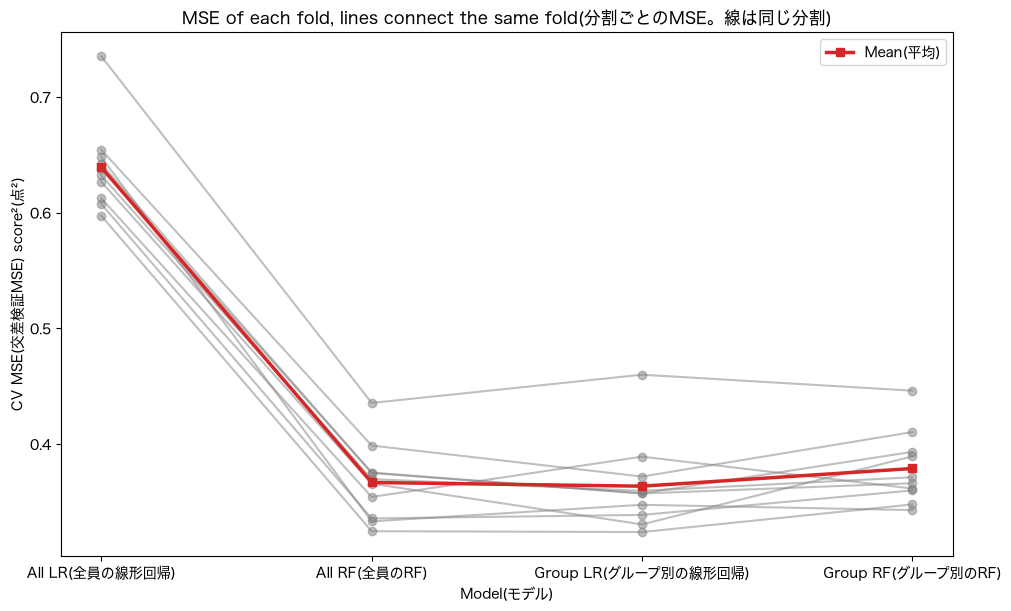

In [28]:
from sklearn.model_selection import StratifiedKFold
from scipy import stats

# 学習データを10分割する。グループで層化し、どの分割にも全グループが入るようにする
N_FOLDS = 10
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
CV_MODELS = ["All LR(全員の線形回帰)", "All RF(全員のRF)", "Group LR(グループ別の線形回帰)", "Group RF(グループ別のRF)"]

fold_rows = []
for k, (tr, va) in enumerate(skf.split(X_train, group_train.astype(str)), start=1):
    X_tr, X_va = X_train.iloc[tr], X_train.iloc[va]
    y_tr, y_va = y_train.iloc[tr], y_train.iloc[va]
    g_tr, g_va = group_train.iloc[tr], group_train.iloc[va]
    pred = pd.DataFrame(index=X_va.index, columns=CV_MODELS, dtype=float)
    pred["All LR(全員の線形回帰)"] = LinearRegression().fit(X_tr, y_tr).predict(X_va)
    rf_all = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **searches[ALL].best_params_)
    pred["All RF(全員のRF)"] = rf_all.fit(X_tr, y_tr).predict(X_va)
    for g in GROUPS:
        in_tr, in_va = g_tr == g, g_va == g
        pred.loc[in_va, "Group LR(グループ別の線形回帰)"] = LinearRegression().fit(X_tr[in_tr], y_tr[in_tr]).predict(X_va[in_va])
        rf_g = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **searches[g].best_params_)
        pred.loc[in_va, "Group RF(グループ別のRF)"] = rf_g.fit(X_tr[in_tr], y_tr[in_tr]).predict(X_va[in_va])
    fold_rows.append({"Fold(分割)": k, "Train N(学習の人数)": len(tr), "Validation N(検証の人数)": len(va)}
                     | {name: mean_squared_error(y_va, pred[name]) for name in CV_MODELS})
fold_table = pd.DataFrame(fold_rows).set_index("Fold(分割)")

# 対応のある t 検定。分割ごとの学習データは重なるので、普通の t 検定は差を大きく見がち
# そのため Nadeau と Bengio の補正（分散に 1/k+検証の人数/学習の人数 を掛ける）をした p値も並べる
PAIRS = [
    ("Group LR(グループ別の線形回帰)", "All LR(全員の線形回帰)"),
    ("Group RF(グループ別のRF)", "All RF(全員のRF)"),
    ("Group LR(グループ別の線形回帰)", "All RF(全員のRF)"),
    ("Group LR(グループ別の線形回帰)", "Group RF(グループ別のRF)"),
    ("All RF(全員のRF)", "All LR(全員の線形回帰)"),
]
ratio = (fold_table["Validation N(検証の人数)"] / fold_table["Train N(学習の人数)"]).mean()
pair_rows = []
for a, b in PAIRS:
    d = fold_table[a] - fold_table[b]
    t, p = stats.ttest_rel(fold_table[a], fold_table[b])
    t_corr = d.mean() / np.sqrt((1 / N_FOLDS + ratio) * d.var())
    p_corr = 2 * stats.t.sf(abs(t_corr), df=N_FOLDS - 1)
    pair_rows.append({
        "Model A(モデルA)": a,
        "Model B(モデルB)": b,
        "Mean A(Aの平均MSE)": fold_table[a].mean(),
        "Mean B(Bの平均MSE)": fold_table[b].mean(),
        "Mean diff A-B(差の平均)": d.mean(),
        "Std diff(差の標準偏差)": d.std(),
        "A better folds(Aが良かった分割の数)": int((d < 0).sum()),
        "df(自由度)": N_FOLDS - 1,
        "t": t,
        "p-value(p値)": p,
        "Corrected t(補正後のt)": t_corr,
        "Corrected p(補正後のp値)": p_corr,
    })
pair_table = pd.DataFrame(pair_rows)

print(f"Folds(分割数):{N_FOLDS}")
print(f"Validation/train ratio(検証の人数/学習の人数):{ratio:.4f}")
print("Fold MSE(分割ごとのMSE):")
print(fold_table.round(4).to_string())
print()
print("Mean fold MSE(分割ごとのMSEの平均):")
print(fold_table[CV_MODELS].mean().round(4).to_string())
print()
print("Paired t-test(対応のあるt検定):")
with pd.option_context("display.float_format", "{:.4g}".format):
    print(pair_table.to_string(index=False))

# 図：分割ごとの MSE（同じ分割を線で結ぶ）
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
for k, row in fold_table[CV_MODELS].iterrows():
    ax.plot(range(len(CV_MODELS)), row.values, color="gray", alpha=0.5, marker="o")
ax.plot(range(len(CV_MODELS)), fold_table[CV_MODELS].mean().values, color="tab:red", marker="s", linewidth=2.5, label="Mean(平均)")
ax.set_xticks(range(len(CV_MODELS)), CV_MODELS)
ax.set_xlabel("Model(モデル)")
ax.set_ylabel("CV MSE(交差検証MSE) score²(点²)")
ax.legend()
ax.set_title("MSE of each fold, lines connect the same fold(分割ごとのMSE。線は同じ分割)")
fig.savefig(f"{FIG_DIR}/paired_cv.png", dpi=150)
plt.show()

## Step 14:Summary(まとめ)

In [29]:
# 研究課題への答えを、特徴量ごとに1つの表にまとめる
summary = pd.DataFrame({
    "Coef unit(係数の単位)": pd.Series(COEF_UNITS),
    "Coef min(係数の最小)": coef_by_group.loc[FEATURES, GROUPS].min(axis=1),
    "Coef max(係数の最大)": coef_by_group.loc[FEATURES, GROUPS].max(axis=1),
    "Group of max |coef|(係数の絶対値が最大のグループ)": coef_by_group.loc[FEATURES, GROUPS].abs().idxmax(axis=1),
    "Interaction p(交互作用の補正後p値)": inter_table["Bonferroni p(ボンフェローニ補正後のp値)"],
    "HC3 p(HC3の補正後p値)": inter_table["HC3 Bonferroni p(HC3の補正後のp値)"],
    "Verdict(判定)": inter_table["Verdict(判定)"],
    "Verdict without 8h+(8h+を除いた判定)": inter_table_no8["Verdict(判定)"],
} | {f"SHAP rank {g}(SHAP順位)": shap_rank[g] for g in GROUPS})
summary.index.name = "Feature(特徴量)"

for verdict in ["Yes(両方で有意)", "HC3 only(HC3だけ有意)", "Classical only(通常だけ有意)", "No(有意でない)"]:
    print(f"{verdict}:all groups(全グループ)={summary.index[summary['Verdict(判定)'] == verdict].tolist()},without 8h+(8h+を除く)={summary.index[summary['Verdict without 8h+(8h+を除いた判定)'] == verdict].tolist()}")
print()
with pd.option_context("display.float_format", "{:.4g}".format):
    print(summary.to_string())
print()
print("Test MSE(テストMSE、Step 9):")
print(mse_table.loc[ALL].round(4).to_string())
print()
print("Saved figures(保存した図):")
for f in sorted(os.listdir(FIG_DIR)):
    print(f"-{FIG_DIR}/{f}")

Yes(両方で有意):all groups(全グループ)=['screen_brightness_pct', 'caffeine_post_5pm_mg', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'morning_alarm_snoozes'],without 8h+(8h+を除く)=['sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'morning_alarm_snoozes']
HC3 only(HC3だけ有意):all groups(全グループ)=['bedtime_phone_minutes', 'blue_light_filter_active'],without 8h+(8h+を除く)=[]
Classical only(通常だけ有意):all groups(全グループ)=[],without 8h+(8h+を除く)=[]
No(有意でない):all groups(全グループ)=['physical_activity_min', 'rem_sleep_pct'],without 8h+(8h+を除く)=['bedtime_phone_minutes', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'rem_sleep_pct']

                               Coef unit(係数の単位)  Coef min(係数の最小)  Coef max(係数の最大) Group of max |coef|(係数の絶対値が最大のグループ)  Interaction p(交互作用の補正後p値)  HC3 p(HC3の補正後p値)        Verdict(判定) Verdict without 8h+(8h+を除いた判定)  SHAP rank -5h(SHAP順位)  SHAP rank 5-6h(SHAP順位)  SHAP rank 6-7h(SHAP順位)  SHAP rank 7-8h(SHAP順位)  SHAP

### Conclusion(結論)

**Answer to the RQ(研究課題への答え):Yes, H0 is rejected(はい。H0 は棄却される)**

The effect of the behavioural factors on next-day fatigue differs across sleep groups(行動要因が翌日の疲労に与える効果は、睡眠時間グループによって異なる). The overall F-test of the 40 interaction terms gives F=53.81, df=(40,6745), p<0.001(交互作用項40個の全体の F 検定)

**1. Prediction(予測)**

- Splitting by sleep group helps linear regression a lot(グループに分けると線形回帰は大きく良くなる):test MSE 0.6308→0.3301. In 10-fold CV the group LR was better in 10 of 10 folds, corrected p=3.9e-10(10分割交差検証では10分割すべてで良く、補正後p=3.9e-10)
- Splitting does not help random forest(RF は良くならない):CV MSE 0.3667→0.3787, worse in 9 of 10 folds, corrected p=0.035(10分割中9分割で悪化)
- Group LR and All RF are not significantly different(グループ別の線形回帰と全員のRFに有意な差はない):corrected p=0.77. A simple equation per group predicts as well as a random forest(グループごとの簡単な式で、RF と同じくらい当たる)
- Tuning the random forest changed test MSE by only 0.0005(RF の調整によるテストMSEの変化は0.0005だけ)

**2. Which effects differ(どの効果が違うか)**

| Feature(特徴量) | All groups(全グループ) | Without 8h+(8h+を除く) |
|---|---|---|
| sleep_latency_min, total_sleep_hours, deep_sleep_pct, morning_alarm_snoozes | Differs(異なる) | Differs(異なる) |
| screen_brightness_pct, caffeine_post_5pm_mg | Differs(異なる) | Not significant(有意でない) |
| bedtime_phone_minutes, blue_light_filter_active | HC3 only(HC3だけ有意) | Not significant(有意でない) |
| physical_activity_min, rem_sleep_pct | Not significant(有意でない) | Not significant(有意でない) |

- The sleep-related factors differ even without 8h+(睡眠に関係する4つは、8h+を除いても効果が異なる). Their effects are strongest around 5.5-6.5h and weaker at both ends(5.5〜6.5時間あたりで最も強く、両端で弱い). Example(例):sleep_latency 0.0134 score/min at the 3-4h window, 0.0425 at 5.5-6.5h, 0.0039 at 8-9h
- The behavioural factors in the RQ (phone, caffeine, brightness, blue light) differ only when 8h+ is included(RQ で挙げた行動要因は、8h+を入れたときだけ効果が異なる). In 8h+ 94.7% of people have fatigue 1.0, so every effect becomes small(8h+ は94.7%が疲労1.0なので、どの効果も小さくなる)
- The weak effects at both ends match the bounds of the fatigue score(両端で効果が弱いのは、疲労スコアの上限・下限への張り付きと合う):40.7% are at 10.0 in the 3-4h window, 100% are at 1.0 at 8.5h and longer(3〜4時間の窓では40.7%が10.0、8.5時間以上では全員が1.0)

**3. SHAP(SHAP)**

- In every group, sleep_latency is the most important feature (38.5-41.2% of mean |SHAP|)(どのグループでも入眠時間が最も重要)
- In the All model, snoozes (36.3%) and sleep hours (35.9%) are the most important(全員のモデルではスヌーズと睡眠時間が最も重要). Inside a group, sleep hours varies only within 1 hour, so its share becomes smaller(グループの中では睡眠時間が1時間の幅しか動かないので、割合が小さくなる)
- The share of caffeine grows with sleep:4.7% in -5h→18.3% in 8h+, rank 5→2(カフェインの割合は睡眠が長いほど大きい). In absolute size it is 0.0135 points in 8h+, so very small(ただし 8h+ での大きさは0.0135点で、ごく小さい)
- Linear regression and SHAP agree on the direction of every feature except physical activity and REM sleep, whose effects were not significant(運動とレム睡眠以外のすべての特徴量で、線形回帰と SHAP の向きが一致。運動とレム睡眠は効果が有意でなかった)

**4. Bedtime phone use(寝る前のスマホ)**

- 60 more minutes of phone use is linked to 0.23-0.36 points more fatigue in -5h to 7-8h, and 0.07 in 8h+(スマホが60分長いと、-5h〜7-8hでは疲労が0.23〜0.36点、8h+では0.07点高い)
- Phone use and sleep latency are strongly correlated (r=0.69-0.86 within groups)(グループ内でも相関が強い). Without sleep_latency and snoozes the phone coefficient becomes 2.5-6.3 times larger(この2つを除くとスマホの係数は2.5〜6.3倍になる). Part of the phone effect may work through longer sleep latency(スマホの効果の一部は、寝つきが遅くなることを通じている可能性がある)

### Limitations(限界)

- Simulated data, not real people(シミュレーションで作られたデータで、実在の人の記録ではない)
- Fatigue is clipped at 1.0 and 10.0, which makes effects look smaller at both ends of sleep(疲労が1.0と10.0で頭打ちになり、睡眠の両端で効果が小さく見える)
- Snoozes may be a result of fatigue, not a cause (reverse causation)(スヌーズは疲労の原因ではなく結果かもしれない＝逆因果)
- Phone use and sleep latency are correlated, so their separate effects are uncertain(スマホと入眠時間は相関が強く、それぞれの効果は分けにくい)
- The classical F-test assumes equal variance in all groups, which does not hold(通常の F 検定は全グループで分散が同じことを仮定するが、成り立たない). The HC3 test is shown for this reason(そのため HC3 の検定も並べた)
- The random forest settings used in the CV comparison were chosen on the whole training data, which slightly favours the random forest(交差検証の比較で使ったRFの設定は学習データ全体で選んだので、RF に少し有利)